# No-spike bins vs position — is the decoder blind in parts of the maze?

Roughly half of the decoder's 6 ms time bins arrive with `spike_count == 0`. In those bins the
posterior is pure transition-model drift — there is no neural evidence at all. The question this
notebook asks: **is that a *place* problem** (the probe samples too few cells, so parts of the maze
have no place-field coverage) **or something else?**

## Two ways to count "spikes in a bin" — read this first

They disagree a lot, and the disagreement is most of the story.

| source | record | what it counts | blind to |
|---|---|---|---|
| **encoder-side** (`enc_spikes`) | `rec_3` `ENCODER_OUTPUT`, one row per spike | every spike Trodes detected whose peak mark exceeded `encoder.spk_amp`, binned by *its own timestamp* into the decoder's 6 ms bins | spikes below the amplitude threshold — those are never written anywhere |
| **decoder-side** (`dec_spikes`) | `rec_4` `DECODER_OUTPUT.spike_count`, one row per bin | spikes that actually reached the decoder *in time* to be used for that bin | nothing extra — but it includes every pipeline loss: late arrival, ring-buffer overwrite, duplicate removal |

- **Encoder-side answers the coverage question.** If tissue near the probe is silent while the
  rat is in a hex, the encoder sees nothing there either.
- **Decoder-side is what the decoder actually had.** It is the number that governs decode quality,
  but it is contaminated by *when* spikes were lost, not just *where* the rat was.

Section 2 shows the two counts drifting apart over the session (pipeline drops grow as the encoding
model grows — see `time_analysis/performance_explained.md` §7). Sections 3–5 map both onto the maze,
split **moving vs still** because still bins in the home hexes dominate occupancy and have far fewer
spikes. Section 6 shows how visit timing leaks into the decoder-side map, and Section 7 lists the
actual no-spike streaks with their recording-clock times.

In [1]:
import os, re, glob, gc, datetime as dt
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import RegularPolygon
import yaml

# categorical order is fixed: blue = encoder-side, orange = decoder-side, aqua = dropped
PAL  = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100',
        '#e87ba4', '#008300', '#4a3aa7', '#e34948']
C_ENC, C_DEC, C_DROP = PAL[0], PAL[1], PAL[2]
C_NOSPIKE = PAL[7]                 # red, reserved for 'no spikes in this bin' marks
INK, INK2, MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, SURF, BASE = '#e1e0d9', '#fcfcfb', '#c3c2b7'
# one-hue sequential ramps (light -> dark). blue for the primary magnitude, orange for a second one
SEQ_BLUE   = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5',
              '#2a78d6', '#256abf', '#1c5cab', '#184f95', '#104281', '#0d366b']
SEQ_ORANGE = ['#fbe4d8', '#f7c4a8', '#f3a57a', '#ee8654', '#eb6834', '#c9501f', '#a03d15',
              '#752a0d', '#4d1a07']
CM_BLUE   = mpl.colors.LinearSegmentedColormap.from_list('seq_blue', SEQ_BLUE)
CM_ORANGE = mpl.colors.LinearSegmentedColormap.from_list('seq_orange', SEQ_ORANGE)

plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2.0, 'font.size': 10.5, 'legend.frameon': False,
    'figure.dpi': 110,
})
def style_ax(ax):
    ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

In [2]:
animal      = 'Vinnie'
date        = '20260812'
session__id = '05'
epoch       = 'r3'
# run folder under /media/ssd1/decoder_output/{animal}/.  None -> f'{date}_{session__id}_{epoch}'
# (Lily/Toby runs follow that pattern; Vinnie runs are named like '20260812_r3_80mv_randomwalk')
RUN_NAME    = '20260812_r3_80mv_randomwalk'

In [3]:
# ---------------- run selection ----------------
if RUN_NAME is None:
    RUN_NAME = f'{date}_{session__id}_{epoch}'
RUN_DIR    = f'/media/ssd1/decoder_output/{animal}/{RUN_NAME}'
RUN_PREFIX = None        # None -> newest *.rec_merged.h5 in RUN_DIR
REC_FILE   = None        # None -> derived from the config's .trodesconf path (for recording_time)

VEL_THRESH = None        # cm/s split for moving / still. None -> the run's encoder.vel_thresh
MIN_BINS   = 300         # a hex needs at least this many bins in a stratum to be coloured on a map
TREND_MIN  = 2           # minutes per point in the time-trend plots
STREAK_MS  = 100         # report no-spike streaks at least this long (ms)

if RUN_PREFIX is None:
    cands = sorted(glob.glob(os.path.join(RUN_DIR, '*.rec_merged.h5')))
    assert cands, f'no *.rec_merged.h5 in {RUN_DIR}'
    RUN_PREFIX = os.path.basename(cands[-1]).replace('.rec_merged.h5', '')

REC = os.path.join(RUN_DIR, RUN_PREFIX + '.rec_merged.h5')
cfg = yaml.safe_load(open(glob.glob(os.path.join(RUN_DIR, RUN_PREFIX + '*.config.yaml'))[0]))

FS       = cfg['sampling_rate']['spikes']
TBIN     = cfg['decoder']['time_bin']['samples']
DELAY    = cfg['decoder']['time_bin']['delay_samples']
POS      = cfg['encoder']['position']
NUM_BINS = POS['num_bins']
assert POS.get('type') == 'hex', 'this notebook draws hex mazes; linear-track runs are not supported'
HEX_IDS  = list(POS['hex_ids'])          # dense posterior index -> real hex id (written at startup)
if VEL_THRESH is None:
    VEL_THRESH = float(cfg['encoder']['vel_thresh'])

print(f'run          : {RUN_PREFIX}')
print(f'time bin     : {TBIN} samples = {TBIN/FS*1e3:.1f} ms   (grace {DELAY/FS*1e3:.1f} ms)')
print(f'hexes        : {NUM_BINS}   ids {HEX_IDS[:6]} ... {HEX_IDS[-3:]}')
print(f'moving/still : |velocity| >= {VEL_THRESH:g} cm/s   (the encoder only *learned* from bins above this)')
print(f'spk_amp      : {cfg["encoder"]["spk_amp"]} µV  -> spikes below this are invisible to every record')
print(f'encoder bufsize {cfg["encoder"]["bufsize"]:,}   frozen_model {cfg["frozen_model"]}   '
      f'train_all_task_states {cfg["encoder"].get("train_all_task_states")}')
print(f'encoder ranks: {cfg["rank"]["encoders"]}   decoder ranks: {cfg["rank"]["decoders"]}')

run          : 20260917_123501_Vinnie_hex_realtime_decoding
time bin     : 180 samples = 6.0 ms   (grace 6.0 ms)
hexes        : 49   ids [1, 2, 3, 4, 5, 6] ... [47, 48, 49]
moving/still : |velocity| >= 10 cm/s   (the encoder only *learned* from bins above this)
spk_amp      : 80 µV  -> spikes below this are invisible to every record
encoder bufsize 3,000,000   frozen_model False   train_all_task_states True
encoder ranks: [4, 5, 6, 7, 8, 9, 10, 11, 12, 13]   decoder ranks: [1]


## 1. Load

`rec_4` gives one row per bin (decoder-side count, velocity, position). `rec_3` gives one row per
amplitude-qualified spike; each spike is placed into the bin whose `[bin_timestamp_l, bin_timestamp_r)`
contains its timestamp — the same window the decoder itself used — to give the encoder-side count.

The recording clock is anchored from the `.rec` header exactly as in `decoder_output_content.ipynb`,
so `recording_time` here is comparable with that notebook's.

In [4]:
# ---------------- recording clock anchor (same method as decoder_output_content.ipynb) ----------------
if REC_FILE is None:
    guess = re.sub(r'\.trodesconf$', '.rec', cfg['trodes']['config_file'])
    REC_FILE = guess if os.path.exists(guess) else None

REC_ANCHOR = None
if REC_FILE and os.path.exists(REC_FILE):
    with open(REC_FILE, 'rb') as f:
        head = f.read(300_000)
    end = head.find(b'</Configuration>')
    xml = head[:end + 16].decode('utf-8', errors='replace') if end > 0 else ''
    def _attr(name):
        m = re.search(rf'{name}\s*=\s*"([^"]*)"', xml)
        return int(m.group(1).strip()) if m and m.group(1).strip() else None
    sys_ms, ts_at = _attr('systemTimeAtCreation'), _attr('timestampAtCreation')
    if sys_ms and ts_at:
        REC_ANCHOR = (sys_ms, ts_at)
        print(f'.rec anchor: {os.path.basename(REC_FILE)}  ->  recording started '
              f'{dt.datetime.fromtimestamp(sys_ms/1000):%Y-%m-%d %H:%M:%S}')
if REC_ANCHOR is None:
    print('no .rec anchor — recording_time will be NaT; seconds-into-session still works')

LOCAL_TZ = dt.datetime.now().astimezone().tzinfo
def to_recording_time(ts):
    """Trodes sample count -> local wall time of the ORIGINAL recording (NaT if no anchor)."""
    ts = np.asarray(ts, np.float64)
    if REC_ANCHOR is None:
        return pd.DatetimeIndex([pd.NaT] * len(ts))
    sys_ms, ts_at = REC_ANCHOR
    ns = np.rint(sys_ms * 1e6 + (ts - ts_at) * (1e9 / FS)).astype(np.int64)
    return pd.to_datetime(ns, unit='ns', utc=True).tz_convert(LOCAL_TZ)

.rec anchor: 20260812_Vinnie_05_r3.rec  ->  recording started 2026-08-12 13:07:19


In [5]:
# ---------------- rec_4: one row per decoded bin ----------------
r4 = pd.read_hdf(REC, 'rec_4')
ranks = sorted(r4.dec_rank.unique())
assert len(ranks) == 1, (f'{len(ranks)} decoder ranks {ranks}: each rank sees only its own trodes, '
                         'so per-rank spike counts must be combined before this analysis')
r4 = r4.sort_values('bin_timestamp_l', kind='stable')

hex_arr = np.asarray(HEX_IDS)
mp = r4.mapped_pos.to_numpy()
ok = np.isfinite(mp) & (mp >= 0) & (mp < NUM_BINS)

bins = pd.DataFrame({
    'trodes_sample': r4.bin_timestamp_l.to_numpy(np.int64),     # bin left edge
    'bin_r'        : r4.bin_timestamp_r.to_numpy(np.int64),
    'dec_spikes'   : r4.spike_count.to_numpy(int),              # what the decoder used
    'dropped_cum'  : r4.dropped_spikes.to_numpy(int),           # decoder's running counter
    'dup_cum'      : r4.duplicated_spikes.to_numpy(int),
    'velocity'     : r4.velocity.to_numpy(float),
    'x'            : r4.x.to_numpy(float),
    'y'            : r4.y.to_numpy(float),
    # mapped_pos is the DENSE index, not a hex id — convert; -1 = position unavailable
    'actual_hex'   : np.where(ok, hex_arr[np.clip(mp, 0, NUM_BINS - 1).astype(int)], -1),
})
del r4; gc.collect()

assert bins.trodes_sample.is_monotonic_increasing and bins.trodes_sample.is_unique
step = np.diff(bins.trodes_sample.to_numpy())
print(f'{len(bins):,} bins  ·  {(step == TBIN).mean()*100:.2f} % tile at exactly {TBIN} samples  ·  '
      f'{(step > TBIN).sum()} gaps')

781,199 bins  ·  100.00 % tile at exactly 180 samples  ·  27 gaps


In [6]:
# ---------------- rec_3: one row per amplitude-qualified spike -> encoder-side count per bin ----------------
r3 = pd.read_hdf(REC, 'rec_3')             # ~850 MB in memory; only three columns are kept
spk = pd.DataFrame({
    'timestamp': r3.timestamp.to_numpy(np.int64),
    'trode'    : r3.elec_grp_id.to_numpy(int),
    # cred_int >= 0  <=>  the KDE produced a likelihood and the spike was sent to the decoder.
    # (performance_explained.md §8: the `sent_to_decoder` column itself is unreliable.)
    'kde_ok'   : r3.cred_int.to_numpy() >= 0,
})
del r3; gc.collect()

# place each spike in the bin whose [left, right) window contains it — the decoder's own rule
left  = bins.trodes_sample.to_numpy()
right = bins.bin_r.to_numpy()
idx   = np.searchsorted(left, spk.timestamp.to_numpy(), side='right') - 1
inside = (idx >= 0) & (spk.timestamp.to_numpy() < right[np.clip(idx, 0, None)])
spk['bin'] = np.where(inside, idx, -1)
spk = spk[spk.bin >= 0].reset_index(drop=True)

bins['enc_spikes']     = np.bincount(spk.bin, minlength=len(bins))
bins['enc_kde_spikes'] = np.bincount(spk.bin[spk.kde_ok], minlength=len(bins))

print(f'spikes at encoder: {inside.sum():,} inside decoded bins ({(~inside).sum():,} outside)')
print(f'  of which produced a likelihood (cred_int >= 0): {spk.kde_ok.mean()*100:.1f} %')
print(f'spikes the decoder used (sum of spike_count)     : {bins.dec_spikes.sum():,}')
print(f'decoder dropped-spike counter, final              : {bins.dropped_cum.iloc[-1]:,}  '
      f'(duplicates removed {bins.dup_cum.iloc[-1]:,})')
print(f'trodes: {sorted(spk.trode.unique())}')

spikes at encoder: 1,714,270 inside decoded bins (15 outside)
  of which produced a likelihood (cred_int >= 0): 95.9 %
spikes the decoder used (sum of spike_count)     : 746,215
decoder dropped-spike counter, final              : 810,120  (duplicates removed 87,304)
trodes: [np.int64(2), np.int64(5), np.int64(8), np.int64(12), np.int64(15), np.int64(18), np.int64(22), np.int64(25), np.int64(28), np.int64(31)]


### The headline table

**What it is.** One row for all bins, one for bins where the rat was moving, one for bins where it was
still. A "bin" is one 6 ms slice of the session; "moving" means the decoder's speed estimate was at or
above the threshold printed in the config cell.

**How to read it.**
- `share_%` — how much of the session that row covers.
- `encoder zero %` — of those bins, how many had *no spike at all* arrive at the encoder. This is the
  closest thing we have to "the brain was quiet".
- `decoder zero %` — of those bins, how many the decoder had to decode with zero spikes. This is what
  actually hurt decoding.
- The two `spikes/bin` columns are the average number of spikes per bin from each source.

**What to look for.** The gap between `encoder zero %` and `decoder zero %` is spikes that existed but
never made it to the decoder in time. If the encoder number is small and the decoder number is large,
the problem is the pipeline, not the tissue. If both are large, the tissue really was quiet.

In [7]:
# ---------------- derived per-bin fields ----------------
bins['sec']            = (bins.trodes_sample - bins.trodes_sample.iloc[0]) / FS
bins['minute']         = bins.sec / 60
bins['recording_time'] = to_recording_time(bins.trodes_sample).to_numpy()
bins['valid_pos']      = bins.actual_hex > 0
bins['moving']         = bins.velocity.abs() >= VEL_THRESH
bins['enc_zero']       = bins.enc_spikes == 0
bins['dec_zero']       = bins.dec_spikes == 0
bins['stratum']        = np.where(bins.moving, 'moving', 'still')

# tag every spike with the hex the rat was in and the movement state of its bin
spk['hex']    = bins.actual_hex.to_numpy()[spk.bin]
spk['moving'] = bins.moving.to_numpy()[spk.bin]
spk['minute'] = bins.minute.to_numpy()[spk.bin]

bin_s = TBIN / FS
def headline(df):
    rows = []
    for name, m in [('all bins', np.ones(len(df), bool)), ('moving', df.moving.to_numpy()),
                    ('still', (~df.moving).to_numpy())]:
        s = df[m]
        rows.append({'stratum': name, 'n_bins': len(s), 'share_%': 100 * len(s) / len(df),
                     'encoder zero %': 100 * s.enc_zero.mean(), 'decoder zero %': 100 * s.dec_zero.mean(),
                     'encoder spikes/bin': s.enc_spikes.mean(), 'decoder spikes/bin': s.dec_spikes.mean()})
    return pd.DataFrame(rows).set_index('stratum').round(2)

print(f'position unavailable in {(~bins.valid_pos).mean()*100:.2f} % of bins')
print(f'home-like occupancy: hex {bins.actual_hex.value_counts().index[0]} holds '
      f'{bins.actual_hex.value_counts(normalize=True).iloc[0]*100:.0f} % of bins, '
      f'hex {bins.actual_hex.value_counts().index[1]} another '
      f'{bins.actual_hex.value_counts(normalize=True).iloc[1]*100:.0f} %')
headline(bins[bins.valid_pos])

position unavailable in 0.00 % of bins
home-like occupancy: hex 2 holds 27 % of bins, hex 1 another 24 %


,n_bins,share_%,encoder zero %,decoder zero %,encoder spikes/bin,decoder spikes/bin
stratum,,,,,,
all bins,781199,100.00,21.87,52.33,2.19,0.96
moving,375131,48.02,14.82,49.76,2.44,1.05
still,406068,51.98,28.38,54.71,1.97,0.87


## 2. First look at *time*, not place

Before mapping anything onto the maze we need to know whether "no spikes" depends on *when* in the
session a bin happened. If it does, every per-hex number is partly a "when did the rat visit this
hex" number, and the maze maps would mislead.

### The two-panel time plot

**What it is.** The session cut into windows of `TREND_MIN` minutes, left to right in time. Only bins
where the rat was moving are used, so the picture is not changed by how long it sat at the reward
wells.

**Top panel.** For each window, the percentage of bins that had no spikes. Blue is the encoder-side
count (spikes that existed), orange is the decoder-side count (spikes the decoder actually got to
use). A flat line means the session was steady; a rising line means things got worse over time.

**Bottom panel.** Raw spike counts per window. Blue: spikes the encoder saw. Orange: spikes the decoder
used. Green: spikes the decoder's own counter says it dropped. Blue should roughly equal orange plus
green.

**What to look for.**
- Blue and orange **on top of each other** in both panels: the decoder received what the brain
  produced; whatever no-spike pattern remains is real.
- Orange **peeling away** from blue with green rising to fill the gap: spikes were lost inside the
  pipeline. This is the known growth failure — the encoding model is neither capped
  (`encoder.bufsize`) nor frozen (`frozen_model`), so the spike-to-position lookup (KDE) slows as the
  model grows, spikes arrive after their bin was already decoded, and get overwritten
  (`time_analysis/performance_explained.md` §7). Every run on the SSD so far is a playback, so live
  pacing may differ, but the mechanism does not.
- **Blue itself sloping down** means the encoder saw fewer spikes late in the session. That is
  upstream of the decoder: electrode drift, spikes shrinking below the amplitude threshold, or the
  animal behaving differently.

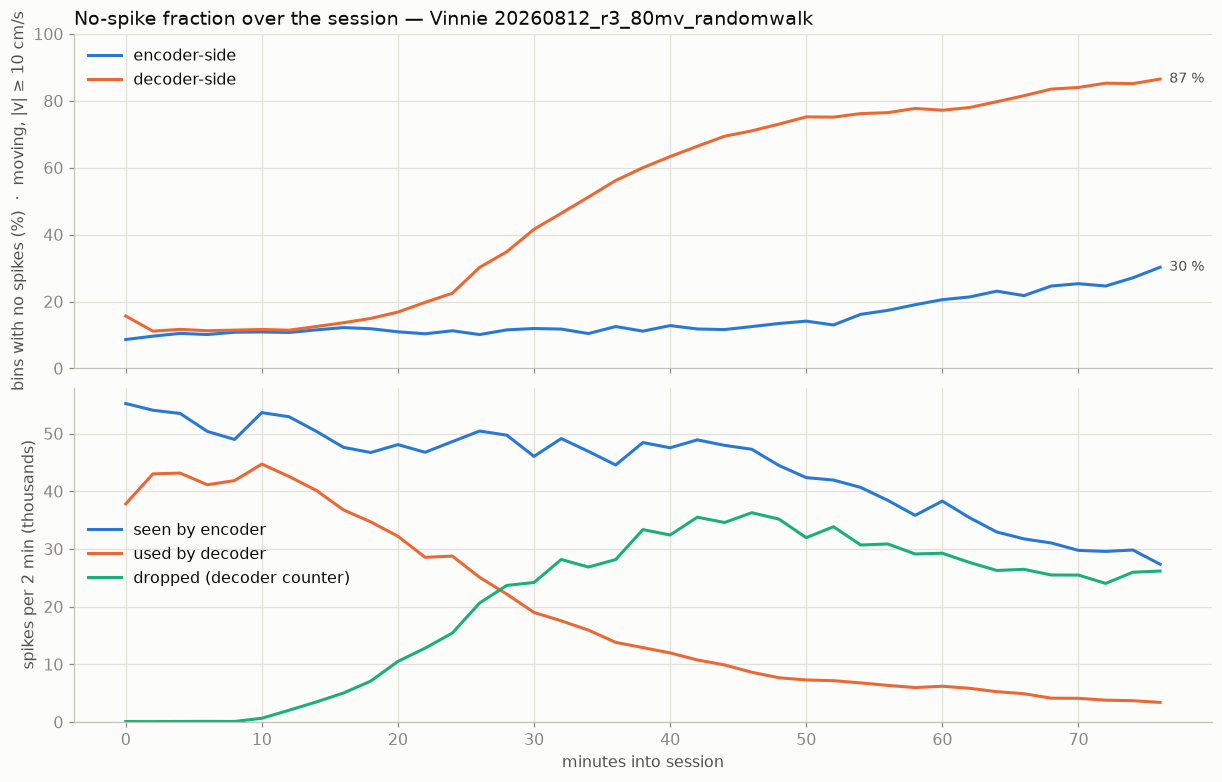

first 10 min vs last 10 min (moving bins):
  encoder-side no-spike bins :  10.0 %  ->   26.4 %
  decoder-side no-spike bins :  12.3 %  ->   84.9 %
  spikes seen by encoder     :   52,421  ->    29,514  per 2 min
  spikes used by decoder     :   41,394  ->     3,841


In [8]:
v  = bins[bins.valid_pos]
tb = (v.minute // TREND_MIN).astype(int) * TREND_MIN
mv = v[v.moving]; tbm = tb[v.moving]

trend = pd.DataFrame({
    'enc_zero_moving': mv.groupby(tbm).enc_zero.mean() * 100,
    'dec_zero_moving': mv.groupby(tbm).dec_zero.mean() * 100,
    'enc_spikes'     : v.groupby(tb).enc_spikes.sum(),
    'dec_spikes'     : v.groupby(tb).dec_spikes.sum(),
    'dropped'        : v.groupby(tb).dropped_cum.max().diff().fillna(v.groupby(tb).dropped_cum.max()),
})
trend = trend[trend.index < trend.index.max()]        # last partial window is not comparable

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, constrained_layout=True)
ax = axes[0]
ax.plot(trend.index, trend.enc_zero_moving, color=C_ENC, label='encoder-side')
ax.plot(trend.index, trend.dec_zero_moving, color=C_DEC, label='decoder-side')
for col, c in [('enc_zero_moving', C_ENC), ('dec_zero_moving', C_DEC)]:
    ax.annotate(f'{trend[col].iloc[-1]:.0f} %', (trend.index[-1], trend[col].iloc[-1]),
                xytext=(6, 0), textcoords='offset points', va='center', color=INK2, fontsize=9)
ax.set_ylabel(f'bins with no spikes (%)  ·  moving, |v| ≥ {VEL_THRESH:g} cm/s')
ax.set_ylim(0, 100); ax.legend(loc='upper left')
ax.set_title(f'No-spike fraction over the session — {animal} {RUN_NAME}', loc='left')
style_ax(ax)

ax = axes[1]
ax.plot(trend.index, trend.enc_spikes / 1e3, color=C_ENC, label='seen by encoder')
ax.plot(trend.index, trend.dec_spikes / 1e3, color=C_DEC, label='used by decoder')
ax.plot(trend.index, trend.dropped  / 1e3, color=C_DROP, label='dropped (decoder counter)')
ax.set_ylabel(f'spikes per {TREND_MIN} min (thousands)'); ax.set_xlabel('minutes into session')
ax.set_ylim(0, None); ax.legend(loc='center left')
style_ax(ax)
plt.show()

first, last = trend.iloc[:5].mean(), trend.iloc[-5:].mean()
print(f'first {5*TREND_MIN} min vs last {5*TREND_MIN} min (moving bins):')
print(f'  encoder-side no-spike bins : {first.enc_zero_moving:5.1f} %  ->  {last.enc_zero_moving:5.1f} %')
print(f'  decoder-side no-spike bins : {first.dec_zero_moving:5.1f} %  ->  {last.dec_zero_moving:5.1f} %')
print(f'  spikes seen by encoder     : {first.enc_spikes:8,.0f}  ->  {last.enc_spikes:8,.0f}  per {TREND_MIN} min')
print(f'  spikes used by decoder     : {first.dec_spikes:8,.0f}  ->  {last.dec_spikes:8,.0f}')

## 3. Per-hex table

**What it is.** One row per hex, computed three times (all bins, moving only, still only) into
`hex_all`, `hex_mov`, `hex_still`. The table shown is the moving-only version, worst coverage at the
top, and only hexes the rat spent at least `MIN_BINS` bins in.

**How to read the columns.**
- `n_bins`, `occupancy_s` — how long the rat spent in that hex (in bins and in seconds).
- `enc_zero_%` — while in that hex, what share of bins had no spike arrive at the encoder. **This is
  the coverage number.** A hex with a high value is a place where the recorded cells were quiet.
- `dec_zero_%` — same, but counting only spikes the decoder actually used. This is what the decoder
  lived with.
- `enc_spikes_per_s` — total spikes per second from all trodes while in that hex. Higher means more
  evidence per unit time. Think of it as a very coarse place-field map for the whole probe.
- `median_visit_min` — the typical time (minutes into the session) the rat was in that hex. Used in
  Section 6 to see whether visit timing explains the decoder-side numbers.

**What to look for.** A hex that is high on `enc_zero_%` *and* low on `enc_spikes_per_s` is a real
coverage gap. A hex that is high on `dec_zero_%` but ordinary on `enc_zero_%` lost its spikes in the
pipeline; check its `median_visit_min` — it is probably late in the session.

In [9]:
def per_hex(df):
    g = df.groupby('actual_hex')
    n = g.size()
    occ_s = n * bin_s
    out = pd.DataFrame({
        'n_bins'          : n,
        'occupancy_s'     : occ_s,
        'enc_zero_%'      : g.enc_zero.mean() * 100,
        'dec_zero_%'      : g.dec_zero.mean() * 100,
        'enc_spikes_per_s': g.enc_spikes.sum() / occ_s,
        'dec_spikes_per_s': g.dec_spikes.sum() / occ_s,
        'median_visit_min': g.minute.median(),
    })
    return out.reindex(HEX_IDS)

hex_all   = per_hex(v)
hex_mov   = per_hex(v[v.moving])
hex_still = per_hex(v[~v.moving])

pd.set_option('display.width', 160)
shown = hex_mov[hex_mov.n_bins >= MIN_BINS].sort_values('enc_zero_%', ascending=False)
print(f'MOVING bins, hexes with >= {MIN_BINS} bins, worst encoder-side coverage first '
      f'({len(shown)} of {NUM_BINS} hexes qualify):')
shown.round(2)

MOVING bins, hexes with >= 300 bins, worst encoder-side coverage first (39 of 49 hexes qualify):


,n_bins,occupancy_s,enc_zero_%,dec_zero_%,enc_spikes_per_s,dec_spikes_per_s,median_visit_min
actual_hex,,,,,,,
15,8297.0,49.78,20.25,69.65,317.48,76.55,42.75
14,2135.0,12.81,19.53,65.34,412.88,119.98,62.09
41,4286.0,25.72,19.02,43.37,350.05,223.25,17.87
12,13643.0,81.86,18.62,56.75,327.10,138.07,39.16
3,6571.0,39.43,18.06,50.92,391.16,172.75,47.57
10,8333.0,50.00,17.29,52.49,381.32,163.21,37.96
6,23211.0,139.27,16.91,53.85,371.66,151.67,37.82
7,15054.0,90.32,16.91,51.93,342.72,154.03,35.10
9,16160.0,96.96,16.69,51.39,347.99,154.53,36.69


## 4. On the maze

Every map in this section is the same drawing: one hexagon per maze cell, placed where the decoder's
own centroid file (`hex_centroid_file`) puts it, in camera pixel coordinates with the image origin at
the top-left — so the maps are oriented the way the video is. The number inside each hexagon is its
hex id. Darker fill means a larger value of whatever that map is showing; the colour bar gives the
scale. **Grey hexagons** had fewer than `MIN_BINS` bins in that stratum, usually because a barrier
blocked them this session and the rat never went there.

In [10]:
# ---------------- hex geometry ----------------
cen = pd.read_csv(POS['hex_centroid_file']).set_index('hex').reindex(HEX_IDS)
assert not cen[['x', 'y']].isna().any().any(), 'centroid file is missing some hex ids from the run config'
XY = cen[['x', 'y']].to_numpy(float)

D = np.hypot(*(XY[:, None, :] - XY[None, :, :]).T); np.fill_diagonal(D, np.inf)
NN = float(np.median(D.min(axis=1)))            # centre-to-centre spacing of neighbouring hexes
# neighbour directions decide whether hexes are pointy-top (neighbours at 0°, 60°, ...) or flat-top
nbr = np.argmin(D, axis=1)
ang = np.degrees(np.arctan2(XY[nbr, 1] - XY[:, 1], XY[nbr, 0] - XY[:, 0])) % 60
pointy_top = np.mean(np.minimum(ang, 60 - ang) < 15) > 0.5
ORIENT = 0.0 if pointy_top else np.pi / 6
R = NN / np.sqrt(3) * 0.96                      # circumradius: flat-to-flat width == NN, with a 2-px-ish gap

def draw_hex_map(ax, values, *, cmap, vmin, vmax, title, n=None, min_n=MIN_BINS, fmt='{:.0f}'):
    """values: Series indexed by hex id. Hexes with n < min_n (or NaN) are drawn grey."""
    norm = mpl.colors.Normalize(vmin, vmax)
    for h, (x, y) in zip(HEX_IDS, XY):
        val = values.get(h, np.nan)
        cnt = None if n is None else n.get(h, 0)
        shown = np.isfinite(val) and (cnt is None or cnt >= min_n)
        face = cmap(norm(val)) if shown else GRID
        ax.add_patch(RegularPolygon((x, y), 6, radius=R, orientation=ORIENT,
                                    facecolor=face, edgecolor=SURF, linewidth=1.5))
        txt = INK if (not shown or norm(val) < 0.55) else SURF
        ax.text(x, y, str(h), ha='center', va='center', fontsize=7, color=txt)
    pad = NN
    ax.set_xlim(XY[:, 0].min() - pad, XY[:, 0].max() + pad)
    ax.set_ylim(XY[:, 1].max() + pad, XY[:, 1].min() - pad)     # image coords: y grows downward
    ax.set_aspect('equal'); ax.axis('off'); ax.grid(False)
    ax.set_title(title, fontsize=10.5, loc='left')
    return mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

print(f'{len(HEX_IDS)} hexes  ·  neighbour spacing {NN:.0f} px  ·  {"pointy" if pointy_top else "flat"}-top')

49 hexes  ·  neighbour spacing 75 px  ·  flat-top


### Figure A — both spike counts, same colour scale

**What it is.** Six maze maps. Each hexagon is coloured by the percentage of bins, *while the rat was
in that hex*, that had no spikes. Top row uses the encoder-side count (spikes that existed); bottom
row uses the decoder-side count (spikes the decoder got to use). Left to right: all bins, moving
bins only, still bins only. All six share one colour bar running 0–100 %.

**How to read it.** Pale means the rat was almost never in that hex without spikes arriving. Dark
means it often was. Compare a hex in the top row with the same hex directly below it.

**What to look for.** If the top row is uniformly pale and the bottom row is dark, the decoder was
starved by the pipeline, not by the brain — the darkness has nothing to do with place. If a hex is
dark in *both* rows, the recorded cells really were quiet there. The "still" column is expected to
be darker than "moving": hippocampal place cells fire less when the animal is not moving.

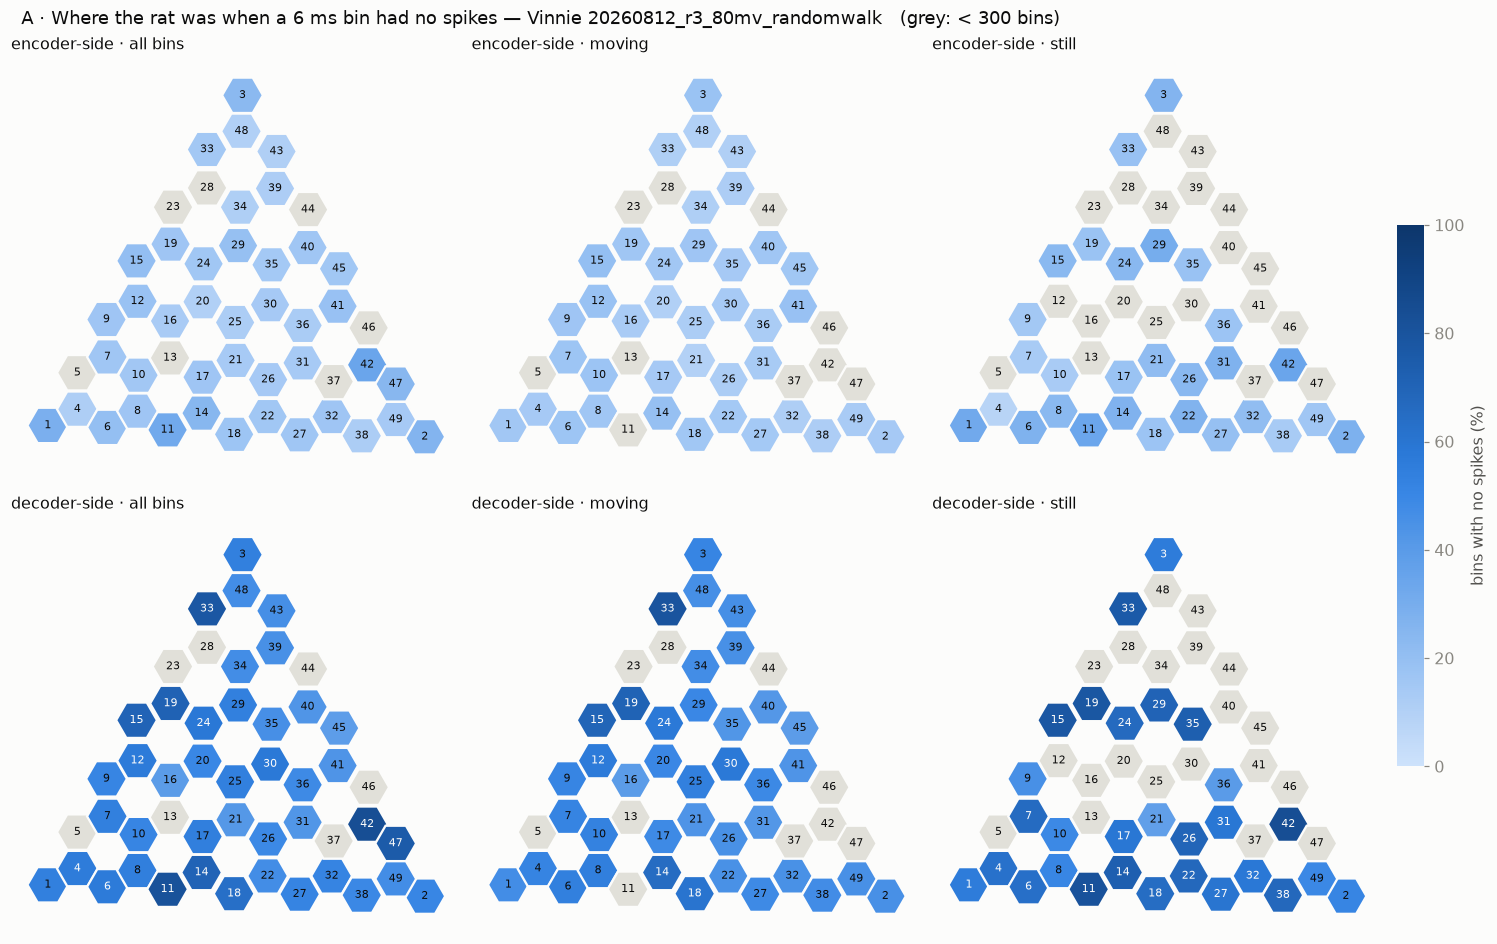

In [11]:
# ---------------- Figure A: both sources, one shared 0-100 % scale ----------------
strata = [('all bins', hex_all), ('moving', hex_mov), ('still', hex_still)]
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.6), constrained_layout=True)
for j, (name, tab) in enumerate(strata):
    sm = draw_hex_map(axes[0, j], tab['enc_zero_%'], n=tab.n_bins, cmap=CM_BLUE, vmin=0, vmax=100,
                      title=f'encoder-side · {name}')
    draw_hex_map(axes[1, j], tab['dec_zero_%'], n=tab.n_bins, cmap=CM_BLUE, vmin=0, vmax=100,
                 title=f'decoder-side · {name}')
cb = fig.colorbar(sm, ax=axes, shrink=0.6, pad=0.01)
cb.set_label('bins with no spikes (%)'); cb.outline.set_visible(False)
fig.suptitle(f'A · Where the rat was when a 6 ms bin had no spikes — {animal} {RUN_NAME}   '
             f'(grey: < {MIN_BINS} bins)', x=0.01, ha='left', fontsize=12)
plt.show()

### Figure B — encoder-side only, zoomed colour scale

**What it is.** The top row of Figure A again, but the colour bar now stops at the largest
encoder-side value instead of 100 %, so small differences between hexes become visible.

**How to read it.** This is the map that answers the original question — *are there parts of the
maze where our probe has no cells firing?* Darker hexes are places with more spike-free bins.

**What to look for.** A cluster of dark hexes in one region of the maze (one arm, one corner) would
point to uneven place-field coverage. Dark hexes scattered at random, or darkness only at the reward
wells in the "still" panel, would not. Read the printed range below the figure: if the darkest hex is
only a few percentage points above the lightest, the gradient is real but small.

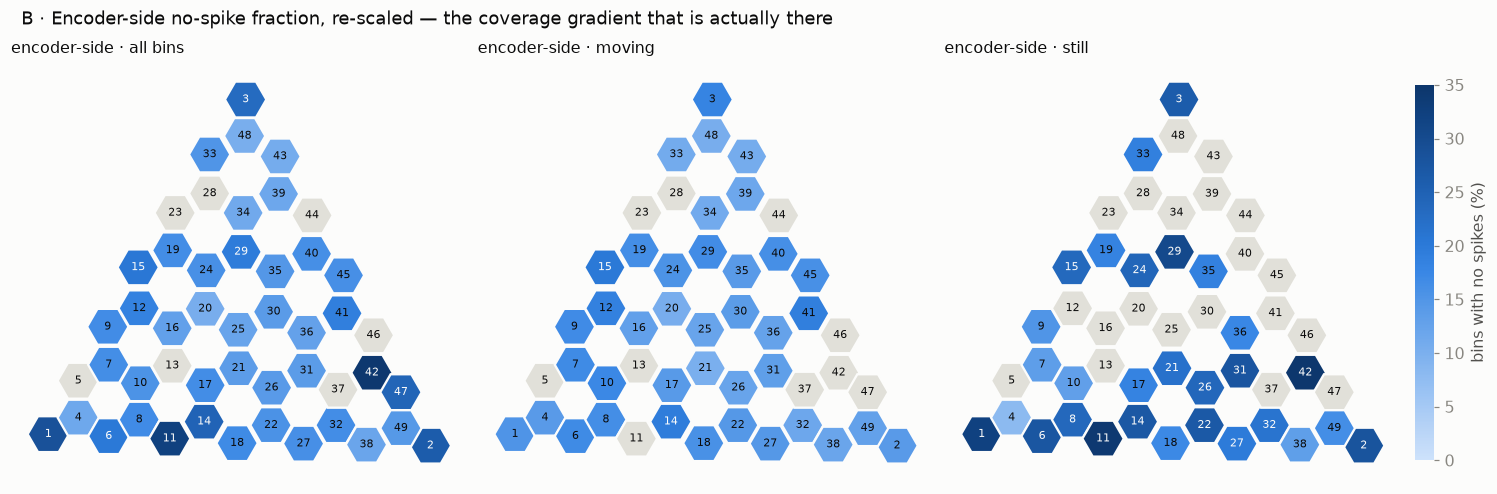

moving bins, encoder-side: no-spike fraction ranges 10.1 % (hex 21) to 20.2 % (hex 15) across 39 hexes
  lowest-evidence hexes : [15, 14, 41, 12, 3, 10, 6, 7]
  best-covered hexes    : [21, 48, 20, 43, 33, 34, 32, 39]


In [12]:
# ---------------- Figure B: encoder-side only, on its own scale ----------------
vmax_enc = np.nanpercentile(pd.concat([t.loc[t.n_bins >= MIN_BINS, 'enc_zero_%'] for _, t in strata]), 98)
vmax_enc = float(np.ceil(vmax_enc / 5) * 5)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.6), constrained_layout=True)
for j, (name, tab) in enumerate(strata):
    sm = draw_hex_map(axes[j], tab['enc_zero_%'], n=tab.n_bins, cmap=CM_BLUE, vmin=0, vmax=vmax_enc,
                      title=f'encoder-side · {name}')
cb = fig.colorbar(sm, ax=axes, shrink=0.8, pad=0.01)
cb.set_label('bins with no spikes (%)'); cb.outline.set_visible(False)
fig.suptitle('B · Encoder-side no-spike fraction, re-scaled — the coverage gradient that is actually there',
             x=0.01, ha='left', fontsize=12)
plt.show()

w = hex_mov[hex_mov.n_bins >= MIN_BINS]['enc_zero_%']
print(f'moving bins, encoder-side: no-spike fraction ranges {w.min():.1f} % (hex {w.idxmin()}) '
      f'to {w.max():.1f} % (hex {w.idxmax()}) across {len(w)} hexes')
print(f'  lowest-evidence hexes : {list(w.sort_values(ascending=False).index[:8])}')
print(f'  best-covered hexes    : {list(w.sort_values().index[:8])}')

### Figure C — how much evidence per second, and where the time went

**What it is.** Two maps side by side.
- **Left (orange):** spikes per second arriving at the encoder while the rat was moving through each
  hex, summed over all trodes. This is a different question from Figures A and B: not "how often was
  there nothing", but "how much was there, on average".
- **Right (blue):** how many seconds the rat spent in each hex over the whole session. The colour
  scale is clipped at the 90th percentile so the one or two hexes the rat parks in do not wash out
  everything else.

**What to look for.** On the left, a hex that is much paler than its neighbours is a place where
the probe hears little. On the right, pale hexes are places the rat barely visited — any number for
those hexes rests on very little data, so treat their values in every other figure with suspicion.
The printed line under the figure names the hexes that hold most of the session.

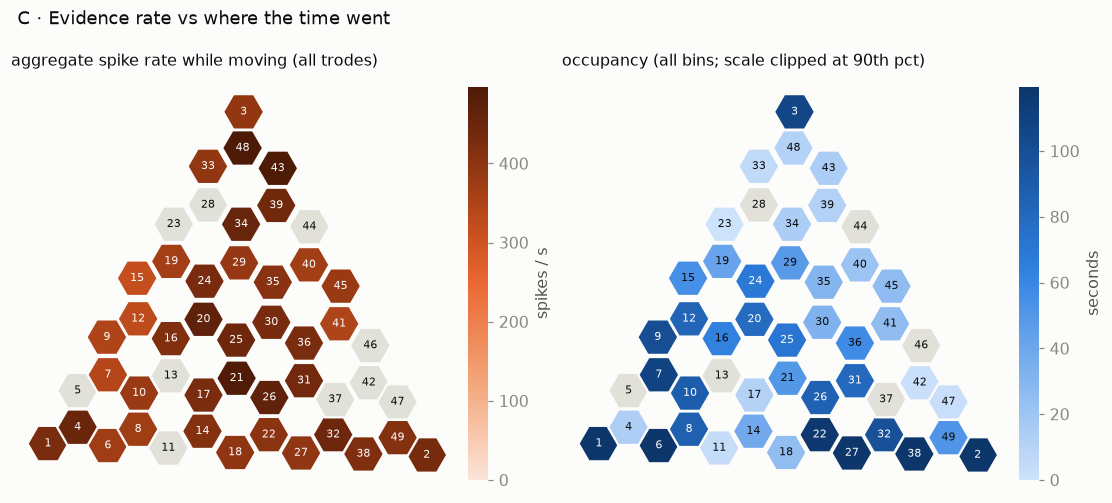

occupancy: hex 2 21.3 min, hex 1 18.6 min, hex 6 3.4 min, hex 27 2.3 min  (of 78.1 min with position)


In [13]:
# ---------------- Figure C: coverage proper — spike rate while moving, and occupancy ----------------
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), constrained_layout=True)
rate = hex_mov['enc_spikes_per_s']
sm = draw_hex_map(axes[0], rate, n=hex_mov.n_bins, cmap=CM_ORANGE, vmin=0,
                  vmax=float(np.nanpercentile(rate[hex_mov.n_bins >= MIN_BINS], 98)),
                  title='aggregate spike rate while moving (all trodes)')
cb = fig.colorbar(sm, ax=axes[0], shrink=0.8, pad=0.01); cb.set_label('spikes / s'); cb.outline.set_visible(False)
occ = hex_all.occupancy_s
sm = draw_hex_map(axes[1], occ, cmap=CM_BLUE, vmin=0, vmax=float(np.nanpercentile(occ, 90)),
                  title='occupancy (all bins; scale clipped at 90th pct)')
cb = fig.colorbar(sm, ax=axes[1], shrink=0.8, pad=0.01); cb.set_label('seconds'); cb.outline.set_visible(False)
fig.suptitle('C · Evidence rate vs where the time went', x=0.01, ha='left', fontsize=12)
plt.show()
top = occ.sort_values(ascending=False)
print('occupancy: ' + ', '.join(f'hex {h} {s/60:.1f} min' for h, s in top.iloc[:4].items())
      + f'  (of {occ.sum()/60:.1f} min with position)')

## 5. Which trode covers which hex?

**What it is.** One maze map per trode (electrode group). Each hexagon is coloured by how many
spikes per second *that trode alone* produced while the rat was moving through that hex. All panels
share one colour bar, so a trode with few spikes looks pale everywhere rather than being stretched to
look busy. The title of each panel gives the trode's total spikes while moving.

**How to read it.** A trode that has a place cell on it should light up in a few neighbouring hexes
and be pale elsewhere — that is what a place field looks like at this resolution. A trode that is
evenly orange everywhere is picking up many cells, or noise. A trode that is pale everywhere is
contributing little.

**What to look for.** Scan down one hex across all the panels. If it is pale in *every* panel, no
trode has a cell that fires there — that is the "not enough cells sampled" case the notebook was
written to find. The printed summary below the figure counts, for each hex, how many trodes fire
there at a meaningful rate, and lists the hexes covered by the fewest.

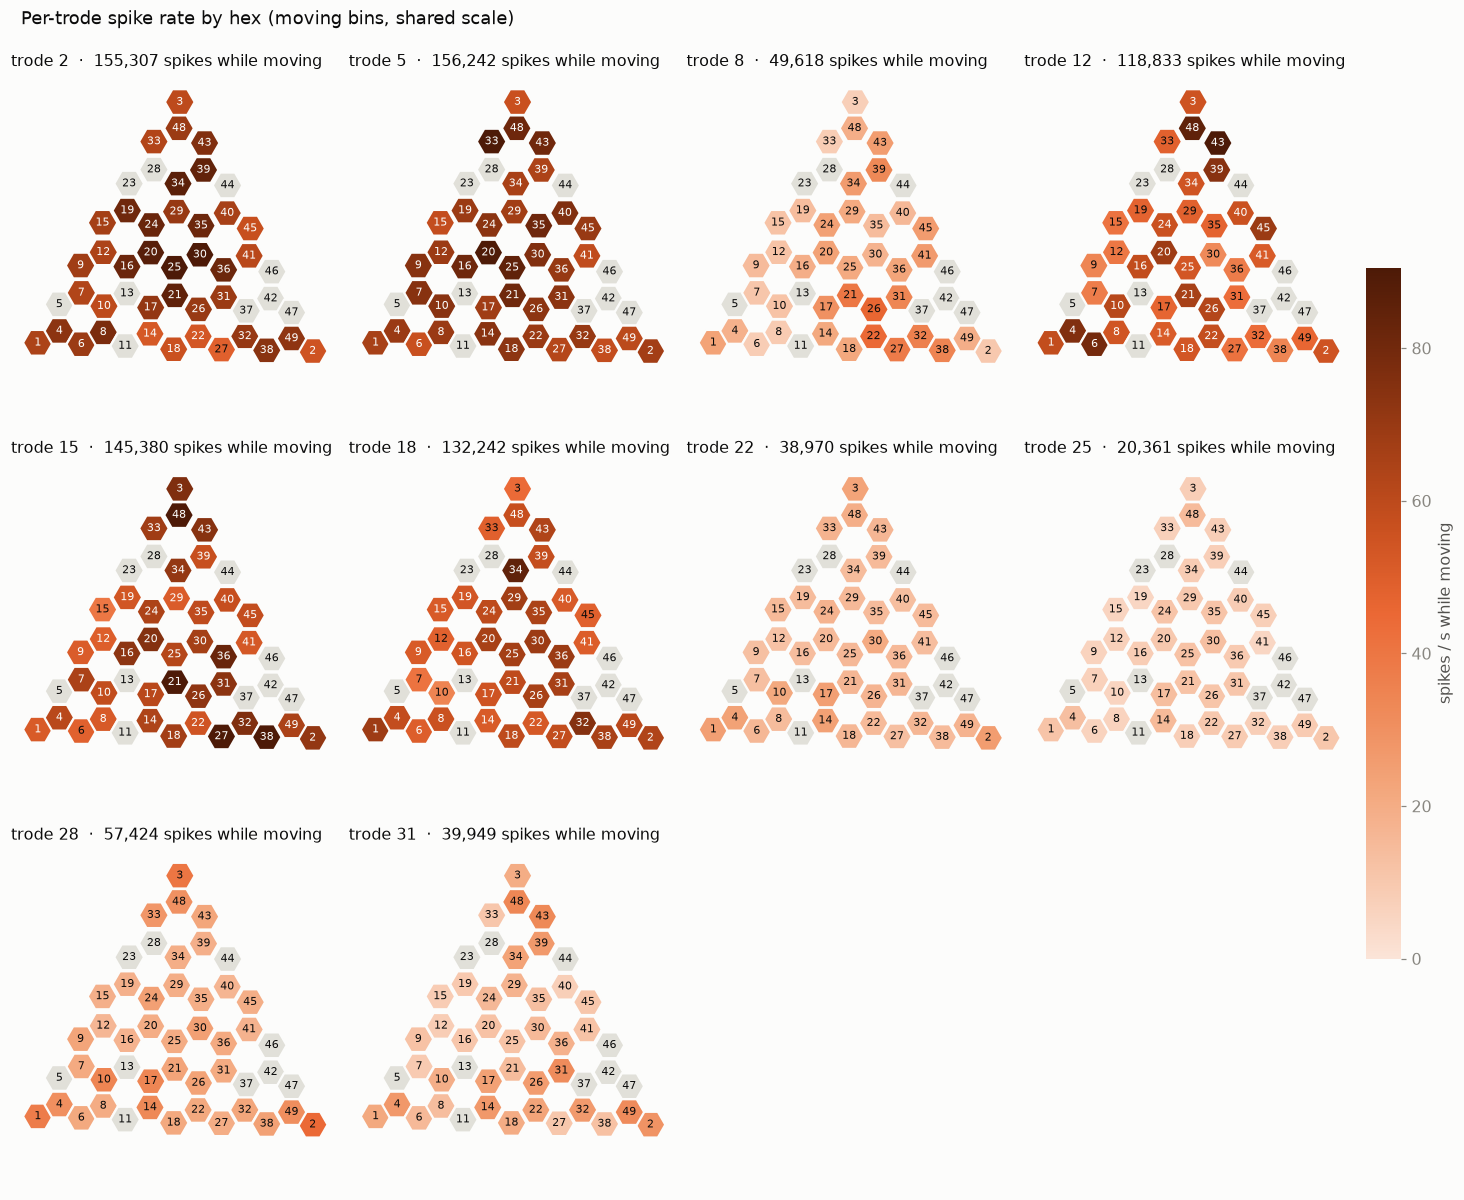

trodes with rate >= 9.46 spikes/s (a quarter of the median cell) per hex:
8.0      7
9.0     16
10.0    16
hexes covered by the fewest trodes: [3, 6, 8, 12, 15, 33, 40, 9]


In [14]:
mv_spk = spk[spk.moving & (spk.hex > 0)]
occ_mov = hex_mov.occupancy_s
trodes = sorted(mv_spk.trode.unique())
rate_by_trode = (mv_spk.groupby(['trode', 'hex']).size().unstack('trode')
                 .reindex(HEX_IDS).fillna(0).div(occ_mov, axis=0))       # spikes / s per trode per hex

ncol = min(4, len(trodes)); nrow = int(np.ceil(len(trodes) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.6 * nrow), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()
vmax_t = float(np.nanpercentile(rate_by_trode[hex_mov.n_bins >= MIN_BINS].to_numpy(), 98))
for ax, t in zip(axes, trodes):
    tot = int((mv_spk.trode == t).sum())
    sm = draw_hex_map(ax, rate_by_trode[t], n=hex_mov.n_bins, cmap=CM_ORANGE, vmin=0, vmax=vmax_t,
                      title=f'trode {t}  ·  {tot:,} spikes while moving')
for ax in axes[len(trodes):]:
    ax.axis('off')
cb = fig.colorbar(sm, ax=axes.tolist(), shrink=0.6, pad=0.01)
cb.set_label('spikes / s while moving'); cb.outline.set_visible(False)
fig.suptitle('Per-trode spike rate by hex (moving bins, shared scale)', x=0.01, ha='left', fontsize=12)
plt.show()

# how many trodes give each hex a meaningful rate?
thr = 0.25 * np.nanmedian(rate_by_trode[hex_mov.n_bins >= MIN_BINS].to_numpy())
n_active = (rate_by_trode >= thr).sum(axis=1).where(hex_mov.n_bins >= MIN_BINS)
print(f'trodes with rate >= {thr:.2f} spikes/s (a quarter of the median cell) per hex:')
print(n_active.value_counts().sort_index().rename('n_hexes').to_string())
print('hexes covered by the fewest trodes:', list(n_active.sort_values().dropna().index[:8]))

## 6. Does the decoder-side map just show *when* the rat visited each hex?

**What it is.** Two scatter plots. Every dot is one hex (its id is printed beside it), using moving
bins only. Dot size is how many bins the rat spent there — big dots are trustworthy, tiny dots are
not.

**Left plot.** Across: the typical time in the session when the rat was in that hex (minutes).
Up: the decoder-side percentage of no-spike bins for that hex. If the dots form a rising line, then
"hexes with no spikes" is really "hexes visited late", because Section 2 showed spikes were being
dropped more and more as the session went on. The Spearman ρ in the corner measures how strongly
the dots rise together (0 = no relation, 1 = perfectly in step).

**Right plot.** Across: encoder-side no-spike percentage. Up: decoder-side no-spike percentage.
The grey diagonal is where a hex would sit if the decoder received every spike the encoder saw.

**What to look for.** On the left, a steep rise means the decoder-side maze maps are mostly a time
effect in disguise. On the right, dots far above the diagonal are hexes whose evidence was lost in
the pipeline; dots near the diagonal are hexes whose numbers mean what they say. Dots far to the
*right* — large encoder-side values — are the real coverage gaps.

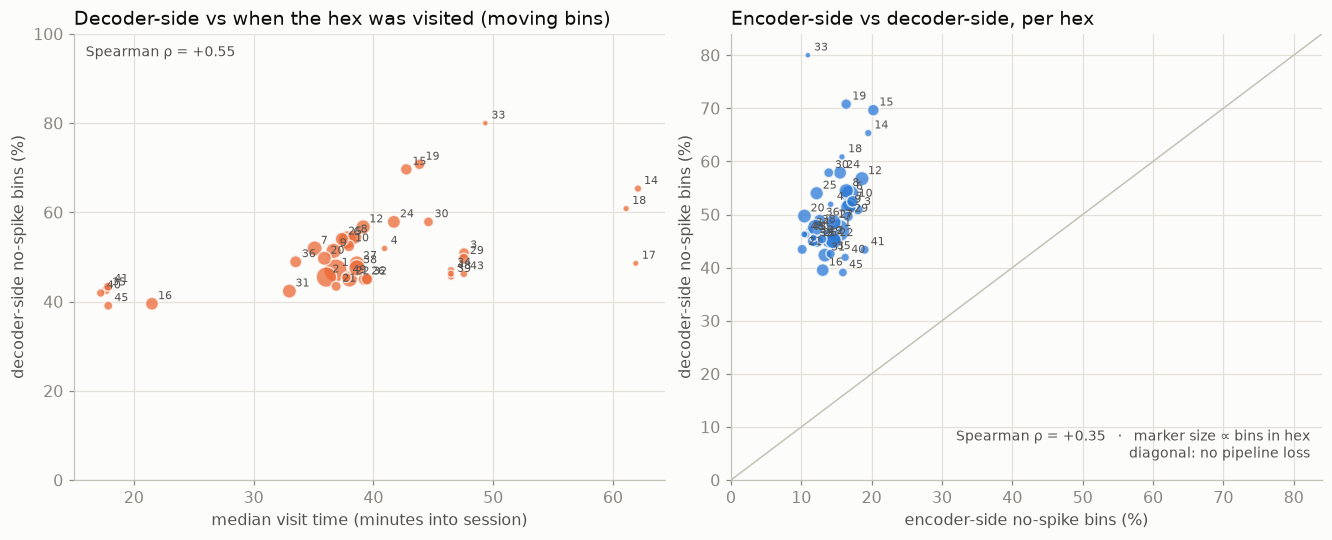

In [15]:
t = hex_mov[hex_mov.n_bins >= MIN_BINS]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
size = 12 + 220 * (t.n_bins / t.n_bins.max())

ax = axes[0]
ax.scatter(t.median_visit_min, t['dec_zero_%'], s=size, color=C_DEC, alpha=0.75,
           edgecolor=SURF, linewidth=1)
for h, r in t.iterrows():
    ax.annotate(str(h), (r.median_visit_min, r['dec_zero_%']), fontsize=7, color=INK2,
                xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('median visit time (minutes into session)'); ax.set_ylabel('decoder-side no-spike bins (%)')
ax.set_ylim(0, 100); ax.set_title('Decoder-side vs when the hex was visited (moving bins)', loc='left')
style_ax(ax)
rho = t[['median_visit_min', 'dec_zero_%']].corr(method='spearman').iloc[0, 1]
ax.annotate(f'Spearman ρ = {rho:+.2f}', (0.02, 0.95), xycoords='axes fraction', color=INK2, fontsize=9)

ax = axes[1]
lim = max(t['dec_zero_%'].max(), t['enc_zero_%'].max()) * 1.05
ax.plot([0, lim], [0, lim], color=BASE, lw=1)
ax.scatter(t['enc_zero_%'], t['dec_zero_%'], s=size, color=C_ENC, alpha=0.75, edgecolor=SURF, linewidth=1)
for h, r in t.iterrows():
    ax.annotate(str(h), (r['enc_zero_%'], r['dec_zero_%']), fontsize=7, color=INK2,
                xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('encoder-side no-spike bins (%)'); ax.set_ylabel('decoder-side no-spike bins (%)')
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_title('Encoder-side vs decoder-side, per hex', loc='left')
style_ax(ax)
rho2 = t[['enc_zero_%', 'dec_zero_%']].corr(method='spearman').iloc[0, 1]
ax.annotate(f'Spearman ρ = {rho2:+.2f}   ·   marker size ∝ bins in hex\ndiagonal: no pipeline loss',
            (0.98, 0.04), xycoords='axes fraction', ha='right', va='bottom', color=INK2, fontsize=9)
plt.show()

## 7. The actual no-spike streaks — when, exactly, and where

A single empty 6 ms bin is unremarkable; the decoder rides through it on its transition model. What
starves the decoder is a *run* of empty bins in a row. This section finds every such run ("streak")
and reports it.

### The streak table

**What it is.** Two tables are built: `streaks_enc` from the encoder-side count and `streaks_dec` from
the decoder-side count. Each row is one streak. The table shown is the twenty longest encoder-side
streaks, longest first.

**How to read the columns.**
- `recording_time` — the wall-clock time of the *original recording* when the streak began (local
  time zone). This is the "exactly what time" answer; it can be looked up in the video or the
  behaviour log.
- `sec_into_session`, `duration_ms` — where it sits in the session, and how long it lasted.
- `hex_at_start` — where the rat was when the streak began.
- `moving_frac` — how much of the streak the rat was moving (1.0 = the whole time, 0.0 = sitting still).
- `velocity_cm_s` — average speed during the streak.

**What to look for.** Long streaks with `moving_frac` near 1 are the interesting ones: the rat was
running through the maze and the probe heard nothing. Long streaks with `moving_frac` at 0 and a
reward-well hex in `hex_at_start` are the animal sitting still, which is expected. The printed lines
above the table count how many streaks pass the `STREAK_MS` length cut in each source, and give the
longest streak that happened while moving.

In [16]:
def streaks(zero_flag, label):
    z = zero_flag.to_numpy()
    edges = np.flatnonzero(np.diff(np.r_[False, z, False]))
    starts, ends = edges[::2], edges[1::2]          # [start, end)
    hex_at   = bins.actual_hex.to_numpy()
    moving   = bins.moving.to_numpy().astype(float)
    df = pd.DataFrame({
        'start_bin'      : starts,
        'n_bins'         : ends - starts,
        'duration_ms'    : (ends - starts) * bin_s * 1e3,
        'sec_into_session': bins.sec.to_numpy()[starts],
        'recording_time' : bins.recording_time.to_numpy()[starts],
        'trodes_sample'  : bins.trodes_sample.to_numpy()[starts],
        'hex_at_start'   : hex_at[starts],
        'moving_frac'    : [moving[s:e].mean() for s, e in zip(starts, ends)],
        'velocity_cm_s'  : [np.abs(bins.velocity.to_numpy()[s:e]).mean() for s, e in zip(starts, ends)],
    })
    df['source'] = label
    return df

streaks_enc = streaks(bins.enc_zero, 'encoder')
streaks_dec = streaks(bins.dec_zero, 'decoder')

for name, s in [('encoder-side', streaks_enc), ('decoder-side', streaks_dec)]:
    long = s[s.duration_ms >= STREAK_MS]
    print(f'{name}: {len(s):,} streaks; {len(long):,} last >= {STREAK_MS} ms, covering '
          f'{long.duration_ms.sum()/1e3:.0f} s of {bins.sec.iloc[-1]:.0f} s; '
          f'longest {s.duration_ms.max()/1e3:.1f} s; '
          f'p50 {s.duration_ms.median():.0f} ms, p95 {s.duration_ms.quantile(.95):.0f} ms')

run_enc = streaks_enc[streaks_enc.moving_frac > 0.5]
print(f'\nencoder-side while MOVING: longest streak {run_enc.duration_ms.max():.0f} ms, '
      f'{(run_enc.duration_ms >= STREAK_MS).sum()} streaks >= {STREAK_MS} ms  '
      f'(vs {(streaks_dec[streaks_dec.moving_frac > 0.5].duration_ms >= STREAK_MS).sum()} decoder-side)')

print(f'\nlongest encoder-side streaks (>= {STREAK_MS} ms):')
cols = ['recording_time', 'sec_into_session', 'duration_ms', 'hex_at_start', 'moving_frac', 'velocity_cm_s']
top_enc = streaks_enc.sort_values('duration_ms', ascending=False).head(20)[cols].copy()
num = top_enc.columns.drop('recording_time')
top_enc[num] = top_enc[num].round(2)
top_enc

encoder-side: 115,845 streaks; 20 last >= 100 ms, covering 2 s of 4687 s; longest 0.2 s; p50 6 ms, p95 18 ms
decoder-side: 136,911 streaks; 2,215 last >= 100 ms, covering 304 s of 4687 s; longest 0.9 s; p50 12 ms, p95 60 ms

encoder-side while MOVING: longest streak 156 ms, 5 streaks >= 100 ms  (vs 1120 decoder-side)

longest encoder-side streaks (>= 100 ms):


,recording_time,sec_into_session,duration_ms,hex_at_start,moving_frac,velocity_cm_s
115523,2026-08-12 14:25:50.098366720-07:00,4677.93,156.0,38,1.0,36.33
115201,2026-08-12 14:25:40.690366720-07:00,4668.52,144.0,1,0.0,1.75
99338,2026-08-12 14:17:28.985700096-07:00,4176.82,138.0,1,0.0,1.57
112110,2026-08-12 14:24:05.619699968-07:00,4573.45,132.0,1,0.0,1.46
113727,2026-08-12 14:24:58.162366720-07:00,4625.99,132.0,2,0.0,0.67
115434,2026-08-12 14:25:47.416366592-07:00,4675.25,126.0,9,1.0,29.25
101648,2026-08-12 14:18:42.293700096-07:00,4250.13,126.0,8,1.0,50.25
108356,2026-08-12 14:22:11.000366592-07:00,4458.83,126.0,7,1.0,45.36
115682,2026-08-12 14:25:54.622366720-07:00,4682.45,120.0,2,0.0,1.68
114761,2026-08-12 14:25:27.910366720-07:00,4655.74,114.0,2,0.0,0.97


### Streak lengths, and where the long ones happen

**What it is.** Three panels.
- **Left:** for every possible streak length (across, in ms, on a log scale), the percentage of
  streaks that lasted *at least* that long (up, also on a log scale). Blue is encoder-side, orange
  is decoder-side. The curve always starts at 100 % on the left (every streak is at least one bin
  long) and falls to the right. The vertical grey line marks the `STREAK_MS` cut used in the maps.
- **Middle and right:** maze maps. For each hex, the number of seconds spent inside long streaks
  (at or above `STREAK_MS`) *per minute the rat spent in that hex*, credited to the hex where each
  streak began. Middle is encoder-side, right is decoder-side, on a shared colour bar.

**How to read it.** In the left panel, the further right a curve reaches before dropping off, the
longer the worst streaks were. The vertical gap between the two curves at any length is the share of
streaks of that length that exist only because of pipeline loss. In the maps, dark means a hex where
the rat spent a large fraction of its time in long silences.

**What to look for.** If the blue curve drops to nothing well before the grey line while the orange
curve continues far past it, essentially every long silence was manufactured by the pipeline. In the
maps, an encoder-side hex that is dark *and* not a reward well is a candidate coverage gap; darkness
only at the reward wells is the animal resting.

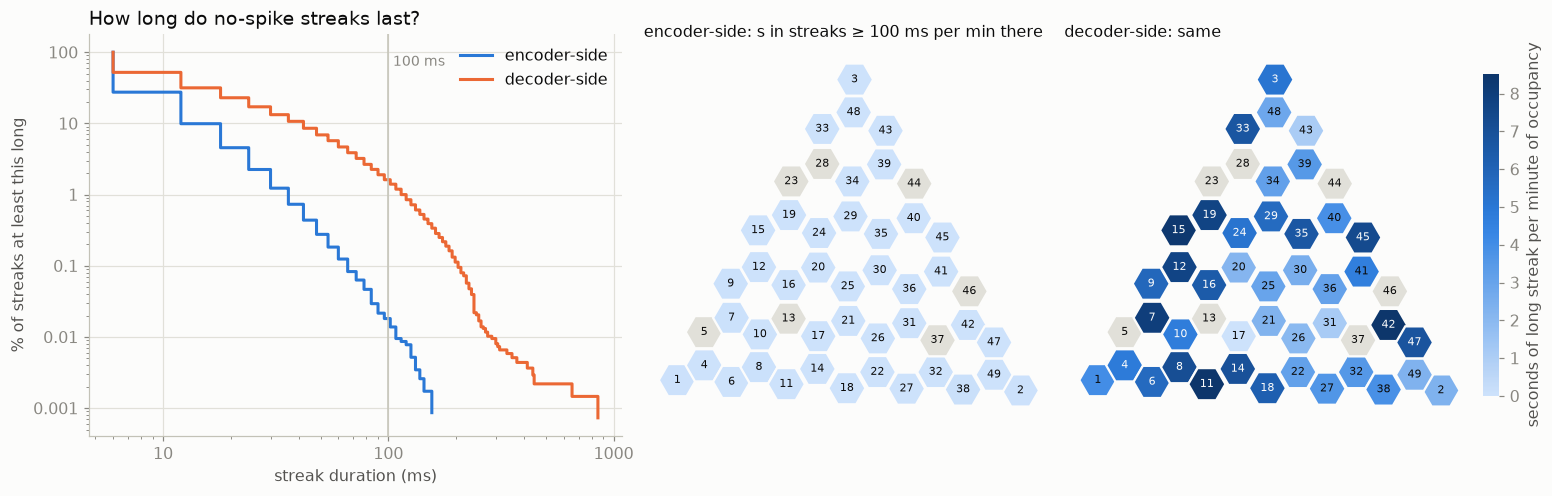

In [17]:
# ---------------- streak duration distributions and where long streaks start ----------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), constrained_layout=True,
                         gridspec_kw={'width_ratios': [1.3, 1, 1]})
ax = axes[0]
# durations are multiples of one bin, so a histogram is a comb; a survival curve reads cleanly
for s, c, lab in [(streaks_enc, C_ENC, 'encoder-side'), (streaks_dec, C_DEC, 'decoder-side')]:
    d = np.sort(s.duration_ms.to_numpy())
    surv = 1 - np.arange(len(d)) / len(d)                     # fraction of streaks lasting >= d
    ax.step(d, surv * 100, where='post', color=c, label=lab)
ax.set_xscale('log'); ax.set_yscale('log')
ax.axvline(STREAK_MS, color=BASE, lw=1)
ax.annotate(f'{STREAK_MS} ms', (STREAK_MS, 100), xytext=(3, -2), textcoords='offset points',
            va='top', color=MUTED, fontsize=9)
ax.set_xlabel('streak duration (ms)'); ax.set_ylabel('% of streaks at least this long')
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}'))
ax.set_title('How long do no-spike streaks last?', loc='left'); ax.legend(loc='upper right')
style_ax(ax)

# seconds per minute of occupancy spent inside long streaks, by hex at streak start
def streak_load(s, tab):
    long = s[(s.duration_ms >= STREAK_MS) & (s.hex_at_start > 0)]
    secs = long.groupby('hex_at_start').duration_ms.sum() / 1e3
    return (secs.reindex(HEX_IDS).fillna(0) / (tab.occupancy_s / 60)).where(tab.n_bins >= MIN_BINS)
load_enc = streak_load(streaks_enc, hex_all); load_dec = streak_load(streaks_dec, hex_all)
vmax_l = float(np.nanpercentile(pd.concat([load_enc, load_dec]), 98))
sm = draw_hex_map(axes[1], load_enc, n=hex_all.n_bins, cmap=CM_BLUE, vmin=0, vmax=vmax_l,
                  title=f'encoder-side: s in streaks ≥ {STREAK_MS} ms per min there')
sm = draw_hex_map(axes[2], load_dec, n=hex_all.n_bins, cmap=CM_BLUE, vmin=0, vmax=vmax_l,
                  title=f'decoder-side: same')
cb = fig.colorbar(sm, ax=axes[1:].tolist(), shrink=0.8, pad=0.01)
cb.set_label('seconds of long streak per minute of occupancy'); cb.outline.set_visible(False)
plt.show()

## 8. Raster view — what a stretch of the session actually looks like

Everything above is a summary. This section shows the raw material for one short window of time,
the way a spike raster would for sorted units. Because the decoder is clusterless there are no
units, so **each trode (electrode group) is treated as one "unit"**: every spike that trode
produced is one tick on its row.

There are **two rasters per window, drawn as separate figures**:

- **Encoding raster** — every amplitude-qualified spike the encoder saw (`rec_3`). This is what the
  brain produced, as far as the recording can tell.
- **Decoding raster** — only the spikes the decoder actually used. The decoder record keeps just a
  per-bin count, so this is rebuilt from the per-spike timing files: a spike is "used" if it reached
  the decoder *before* its bin's posterior was computed and survived the duplicate-timestamp rule.
  The load cell prints how well that reconstruction matches the decoder's own `spike_count`
  (typically exact in ~98 % of bins; the small excess is spikes overwritten in the decoder's buffer,
  which the timing files cannot see).

The difference between the two figures for the same window is, spike by spike, what the pipeline
lost.

### The window plot

**What it is.** One figure for a window of `dur` seconds starting `t0` seconds into the session, all
panels sharing the same time axis (seconds into the session along the bottom; the window's start on
the recording clock is in the title). From top to bottom:

1. **Raster.** One row per trode, one tick per spike from the figure's source (encoder or decoder,
   named in the title). Dense rows are busy trodes. **Red vertical bands mark every 6 ms decoder bin
   that had no spike at all from this source** — on the decoding raster these are exactly the bins
   the decoder had to fill from the transition model alone. Consecutive empty bins merge into a
   wider band; the note above the panel gives their share of the window.
2. **Speed.** The decoder's speed estimate for each 6 ms bin, in cm/s. The grey line is the
   moving/still threshold; the shaded band marks bins where the rat was moving.
3. **MUA per trode** (multi-unit activity). One small line per trode, same order as the raster
   rows, from the same source as the raster: spikes counted in `MUA_BIN_MS` bins, converted to spikes per second, and lightly smoothed
   with a Gaussian of width `MUA_SMOOTH_MS` so the line reads as a firing rate rather than a comb.
   All traces share
   one vertical scale, so a busy trode really looks busier than a quiet one. It is the raster
   re-drawn as a rate, so a heavy burst and a lone spike are told apart.
4. **Summed MUA.** The same smoothed rate added over all trodes. Both sources are always shown here
   so the two figures can be compared: blue is the encoder-side total (spikes that existed); orange
   is the decoder-side total (spikes the decoder actually used) for the same bins.

**What to look for.** Rows in the raster that fire only when speed is high are behaving like place
cells. If the orange summed-MUA line sits well below the blue one, spikes were lost in the pipeline
during this window; compare an early window with a late one. Bins where blue is above zero and
orange is at zero are exactly the "decoder had no evidence" bins this notebook is about. A busy
trode whose row breaks into blocks with clean gaps, while quiet trodes stay continuous, is an
encoder rank that has fallen behind the live stream (see Caveats) — not silent tissue.

`plot_window(t0, dur, source='encoder' | 'decoder')` draws one window from one source;
`pick_window(...)` chooses a window with a lot of running in a given part of the session;
`tile_session(...)` below draws every window of the session into two multi-page PDFs (one per
source, same page numbering).

decoder received 1,643,875 spikes; 49.3 % arrived late; 746,215 reconstructed as used vs 746,215 recorded
  per-bin match with rec_4.spike_count: exact in 100.0 % of bins, over by 0.0 % (buffer-overwritten spikes the timing files cannot see), under in 0.00 %
window 143.7-153.7 s: 5,188 spikes at encoder, 4,252 used by decoder (18 % lost)  ·  moving 85 % of the window  ·  bins with no decoder spikes 13 %, no encoder spikes 11 %


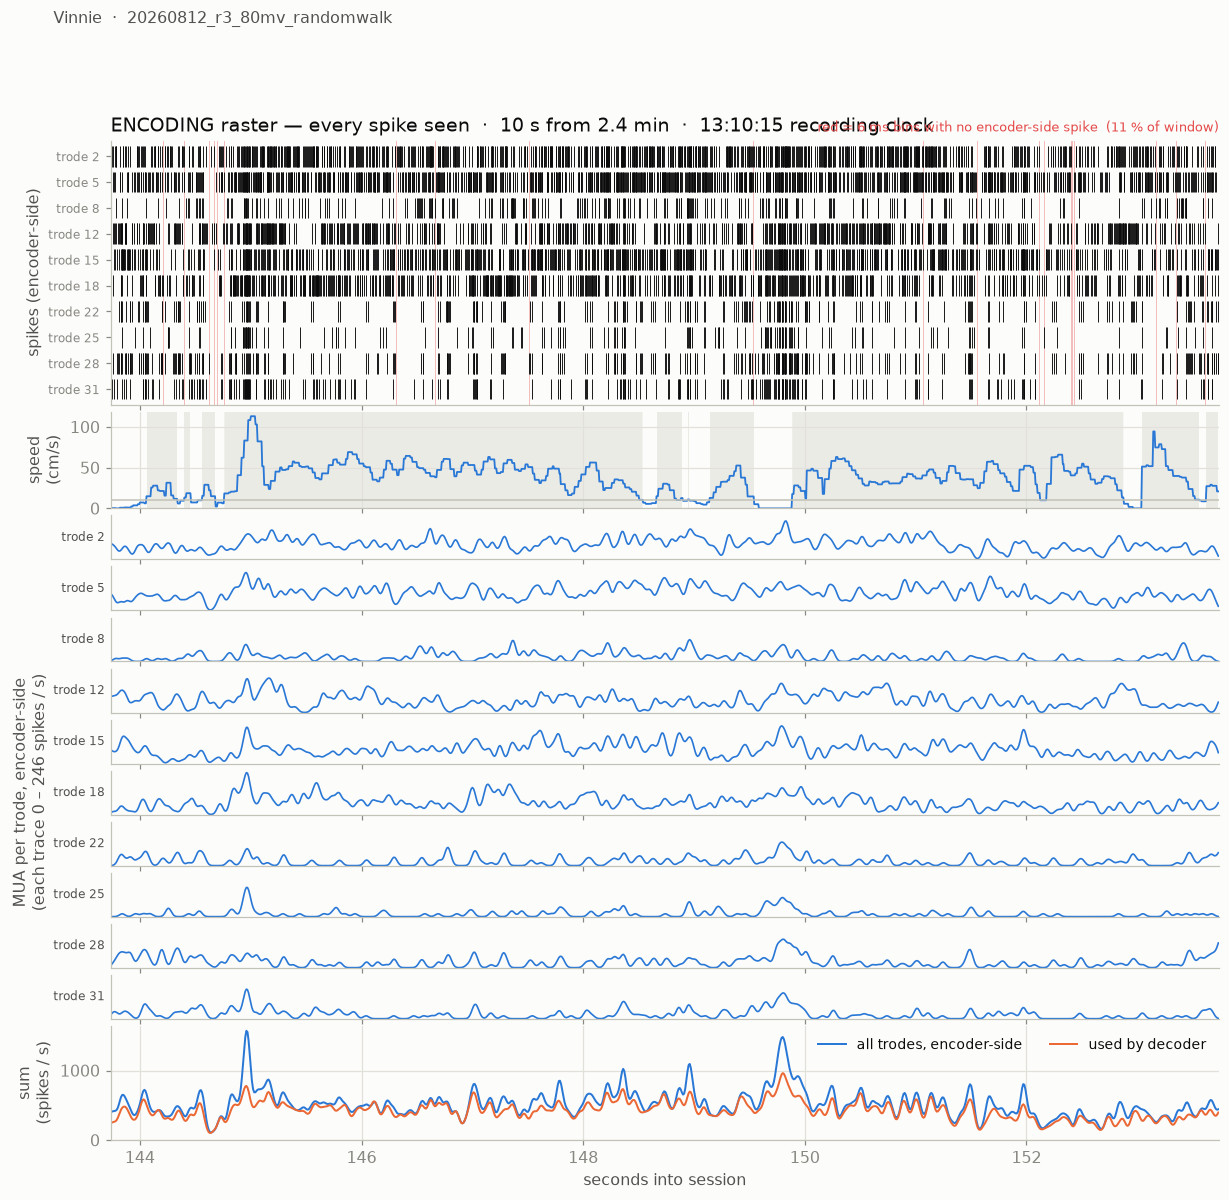

In [18]:
# ---------------- decoder-used spikes, rebuilt from the per-spike timing files ----------------
TIM = os.path.join(RUN_DIR, RUN_PREFIX + '.timings_merged.h5')
spk_dec = None
if os.path.exists(TIM):
    _sp   = pd.read_hdf(TIM, 'spikes')                      # 1 row per spike the decoder RECEIVED
    _post = pd.read_hdf(TIM, 'posterior').sort_values('bin_timestamp_l', ignore_index=True)
    assert np.array_equal(_post.bin_timestamp_l.to_numpy(), bins.trodes_sample.to_numpy()), \
        'timing posterior rows do not line up with rec_4 bins'
    _ts  = _sp.timestamp.to_numpy(np.int64)
    _idx = np.searchsorted(left, _ts, side='right') - 1
    _in  = (_idx >= 0) & (_ts < right[np.clip(_idx, 0, None)])
    _sp  = _sp[_in].copy(); _sp['bin'] = _idx[_in]
    # late = arrived after the bin's posterior had already started -> could not be used
    _sp['late'] = _sp.t_decoder.to_numpy() >= _post.t_start_post.to_numpy()[_sp.bin]
    _on = _sp[~_sp.late]
    # decoder's duplicate rule (_get_unique): identical timestamps within a bin -> keep one if it
    # occurs once or twice, drop all if it occurs three or more times
    _mult = _on.groupby(['bin', 'timestamp']).timestamp.transform('size')
    _on   = _on[_mult < 3].drop_duplicates(['bin', 'timestamp'])
    spk_dec = pd.DataFrame({'timestamp': _on.timestamp.to_numpy(np.int64),
                            'trode'    : _on.elec_grp_id.to_numpy(int),
                            'bin'      : _on.bin.to_numpy(int)}).reset_index(drop=True)
    spk_dec['sec'] = (spk_dec.timestamp - bins.trodes_sample.iloc[0]) / FS
    _cnt = np.bincount(spk_dec.bin, minlength=len(bins))
    _rec = bins.dec_spikes.to_numpy()
    print(f'decoder received {len(_sp):,} spikes; {_sp.late.mean()*100:.1f} % arrived late; '
          f'{len(spk_dec):,} reconstructed as used vs {_rec.sum():,} recorded')
    print(f'  per-bin match with rec_4.spike_count: exact in {(_cnt == _rec).mean()*100:.1f} % of bins, '
          f'over by {(_cnt > _rec).mean()*100:.1f} % (buffer-overwritten spikes the timing files cannot see), '
          f'under in {(_cnt < _rec).mean()*100:.2f} %')
    del _sp, _post, _on; gc.collect()
else:
    print(f'no timings file ({TIM}) -- decoding raster unavailable, encoder raster only')

MUA_BIN_MS    = 10.0             # ms per MUA bin before smoothing
MUA_SMOOTH_MS = 25.0             # Gaussian smoothing width (sigma, ms) for the MUA lines; 0 = raw counts
from scipy.ndimage import gaussian_filter1d
def smooth(counts, bin_ms, sigma_ms=None):
    """Gaussian-smooth a count series along time and convert to a rate in spikes / s."""
    sigma_ms = MUA_SMOOTH_MS if sigma_ms is None else sigma_ms
    rate = np.asarray(counts, float) * (1e3 / bin_ms)
    if sigma_ms <= 0:
        return rate
    return gaussian_filter1d(rate, sigma=sigma_ms / bin_ms, mode='nearest', axis=-1)
spk['sec'] = (spk.timestamp - bins.trodes_sample.iloc[0]) / FS
TRODES = sorted(spk.trode.unique())

def pick_window(min_start, min_end, dur=30.0):
    """Start time (s) of the `dur`-second window between two minute marks with the most moving bins."""
    lo, hi = min_start * 60, min_end * 60
    cand = bins[(bins.sec >= lo) & (bins.sec < hi)]
    n = int(round(dur / bin_s))
    mv = cand.moving.to_numpy().astype(float)
    if len(mv) <= n:
        return float(lo)
    roll = np.convolve(mv, np.ones(n), mode='valid')            # moving bins in each candidate window
    return float(cand.sec.to_numpy()[int(np.argmax(roll))])

def window_stats(t0, dur=30.0):
    """One-row summary of a window: spikes at encoder / used by decoder, moving share, no-spike shares."""
    b = bins[(bins.sec >= t0) & (bins.sec < t0 + dur)]
    enc = int(b.enc_spikes.sum()); dec = int(b.dec_spikes.sum())
    return {'t0_s': t0, 'minute': t0 / 60,
            'recording_time': to_recording_time([b.trodes_sample.iloc[0]])[0] if len(b) else pd.NaT,
            'enc_spikes': enc, 'dec_spikes': dec, 'lost_%': 100 * (enc - dec) / max(enc, 1),
            'moving_%': 100 * b.moving.mean() if len(b) else np.nan,
            'dec_zero_%': 100 * b.dec_zero.mean() if len(b) else np.nan,
            'enc_zero_%': 100 * b.enc_zero.mean() if len(b) else np.nan,
            'hexes': ' '.join(str(h) for h in pd.unique(b.actual_hex[b.actual_hex > 0]))}

def plot_window(t0, dur=30.0, source='encoder', mua_bin_ms=None, title=None, mua_vmax=None, show=True):
    """source: 'encoder' = every amplitude-qualified spike; 'decoder' = spikes the decoder used."""
    assert source in ('encoder', 'decoder')
    if source == 'decoder' and spk_dec is None:
        raise RuntimeError('decoder raster needs the timings_merged.h5 file for this run')
    src = spk if source == 'encoder' else spk_dec
    mua_bin_ms = MUA_BIN_MS if mua_bin_ms is None else mua_bin_ms
    t1 = t0 + dur
    s = src[(src.sec >= t0) & (src.sec < t1)]
    b = bins[(bins.sec >= t0) & (bins.sec < t1)]
    edges = np.arange(t0, t1 + 1e-9, mua_bin_ms / 1e3)
    centers = edges[:-1] + mua_bin_ms / 2e3

    mua = smooth(np.vstack([np.histogram(s.sec[s.trode == t], bins=edges)[0] for t in TRODES]), mua_bin_ms)
    # the summed panel always shows BOTH sources so the two figures can be compared
    enc_sum = smooth(np.histogram(spk.sec[(spk.sec >= t0) & (spk.sec < t1)], bins=edges)[0], mua_bin_ms)
    dec_sum = smooth(np.histogram(b.sec, bins=edges, weights=b.dec_spikes)[0], mua_bin_ms)
    if mua_vmax is None:
        mua_vmax = max(10.0, float(mua.max()) * 1.05)     # single window: fit its own peak

    n_t = len(TRODES)
    heights = [max(2.6, 0.30 * n_t), 1.1] + [0.5] * n_t + [1.3]
    fig, axes = plt.subplots(len(heights), 1, figsize=(13, sum(heights) + 1.4), sharex=True,
                             gridspec_kw={'height_ratios': heights, 'hspace': 0.10})
    ax_r, ax_v, ax_m, ax_s = axes[0], axes[1], axes[2:2 + n_t], axes[-1]

    # 1 · raster: one row per trode, one tick per spike. Everything is drawn as vectors: matplotlib
    #     keeps each rasterized image in memory until a PDF is closed (~0.2 GB per page here), which
    #     made tile_session run the kernel out of memory. Vector pages are also smaller.
    #     Red vertical bands = 6 ms decoder bins with NO spike from this figure's source.
    zero = (b.enc_zero if source == 'encoder' else b.dec_zero).to_numpy()
    if zero.any():
        edges_b = np.r_[b.sec.to_numpy(), b.sec.iloc[-1] + bin_s]
        ax_r.fill_between(edges_b, 0, 1, where=np.r_[zero, False], step='post',
                          transform=ax_r.get_xaxis_transform(), color=C_NOSPIKE, alpha=0.35,
                          linewidth=0, zorder=0)
    ax_r.eventplot([s.sec[s.trode == t].to_numpy() for t in TRODES], lineoffsets=np.arange(n_t),
                   linelengths=0.8, linewidths=0.6, colors=INK)
    ax_r.set_yticks(np.arange(n_t)); ax_r.set_yticklabels([f'trode {t}' for t in TRODES], fontsize=8)
    ax_r.set_ylim(-0.6, n_t - 0.4); ax_r.invert_yaxis(); ax_r.grid(False)
    ax_r.set_ylabel(f'spikes ({source}-side)')
    ax_r.set_title(f'red = 6 ms bins with no {source}-side spike  ({zero.mean()*100:.0f} % of window)',
                   loc='right', fontsize=8.5, color=C_NOSPIKE)
    rt = to_recording_time([b.trodes_sample.iloc[0]])[0] if len(b) else pd.NaT
    label = 'ENCODING raster — every spike seen' if source == 'encoder' else 'DECODING raster — spikes the decoder used'
    ax_r.set_title(title or f'{label}  ·  {dur:.0f} s from {t0/60:.1f} min'
                   + (f'  ·  {rt:%H:%M:%S} recording clock' if pd.notna(rt) else ''), loc='left')
    fig.suptitle(f'{animal}  ·  {RUN_NAME}', x=0.085, ha='left', fontsize=10.5, color=INK2)
    style_ax(ax_r)

    # 2 · speed, with the moving/still threshold and moving bins shaded
    ax_v.fill_between(b.sec, 0, 1, where=b.moving, transform=ax_v.get_xaxis_transform(),
                      color=GRID, alpha=0.6, linewidth=0, step='post')
    ax_v.plot(b.sec, b.velocity.abs(), color=C_ENC, lw=1.2)
    ax_v.axhline(VEL_THRESH, color=BASE, lw=1)
    ax_v.set_ylabel('speed\n(cm/s)'); ax_v.set_ylim(0, None)
    style_ax(ax_v)

    # 3 · MUA per trode: stacked traces on one shared vertical scale
    for ax, t, row in zip(ax_m, TRODES, mua):
        ax.plot(centers, row, color=C_ENC, lw=1.1)
        ax.set_ylim(0, mua_vmax); ax.set_yticks([])
        ax.text(-0.005, 0.5, f'trode {t}', transform=ax.transAxes, ha='right', va='center',
                fontsize=8, color=INK2)
        ax.grid(False); style_ax(ax)
    ax_m[n_t // 2].set_ylabel(f'MUA per trode, {source}-side\n(each trace 0 – {mua_vmax:.0f} spikes / s)',
                              labelpad=40)

    # 4 · summed MUA: encoder-side vs decoder-used
    ax_s.plot(centers, enc_sum, color=C_ENC, lw=1.3, label='all trodes, encoder-side')
    ax_s.plot(centers, dec_sum, color=C_DEC, lw=1.3, label='used by decoder')
    ax_s.set_ylabel('sum\n(spikes / s)'); ax_s.set_xlabel('seconds into session')
    ax_s.set_ylim(0, None); ax_s.legend(loc='upper right', fontsize=9, ncol=2)
    style_ax(ax_s)
    ax_s.set_xlim(t0, t1)

    st = window_stats(t0, dur)
    if show:
        print(f"window {t0:.1f}-{t1:.1f} s: {st['enc_spikes']:,} spikes at encoder, "
              f"{st['dec_spikes']:,} used by decoder ({st['lost_%']:.0f} % lost)  ·  "
              f"moving {st['moving_%']:.0f} % of the window  ·  bins with no decoder spikes "
              f"{st['dec_zero_%']:.0f} %, no encoder spikes {st['enc_zero_%']:.0f} %")
        plt.show()
    return fig

DEMO_DUR = 10.0
t_early = pick_window(2, 12, DEMO_DUR)                                   # early: before drops set in
t_late  = pick_window(bins.minute.max() - 12, bins.minute.max() - 1, DEMO_DUR)
_ = plot_window(t_early, DEMO_DUR, source='encoder')

window 143.7-153.7 s: 5,188 spikes at encoder, 4,252 used by decoder (18 % lost)  ·  moving 85 % of the window  ·  bins with no decoder spikes 13 %, no encoder spikes 11 %


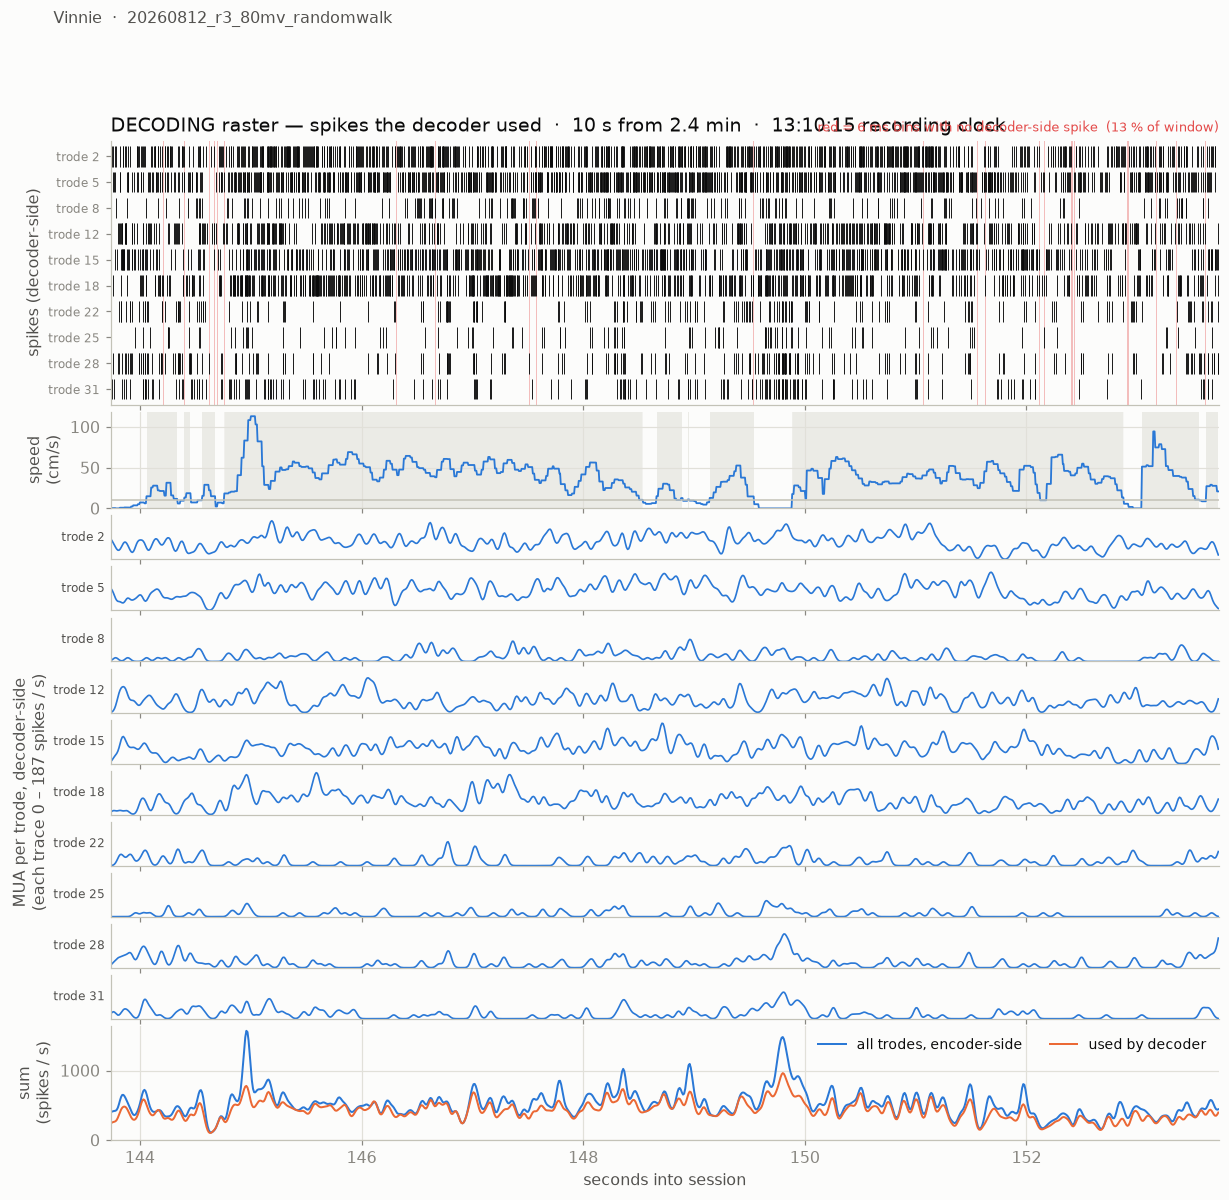

In [19]:
_ = plot_window(t_early, DEMO_DUR, source='decoder')

The same two figures for a window late in the session.

window 4047.7-4057.7 s: 2,749 spikes at encoder, 395 used by decoder (86 % lost)  ·  moving 83 % of the window  ·  bins with no decoder spikes 81 %, no encoder spikes 27 %


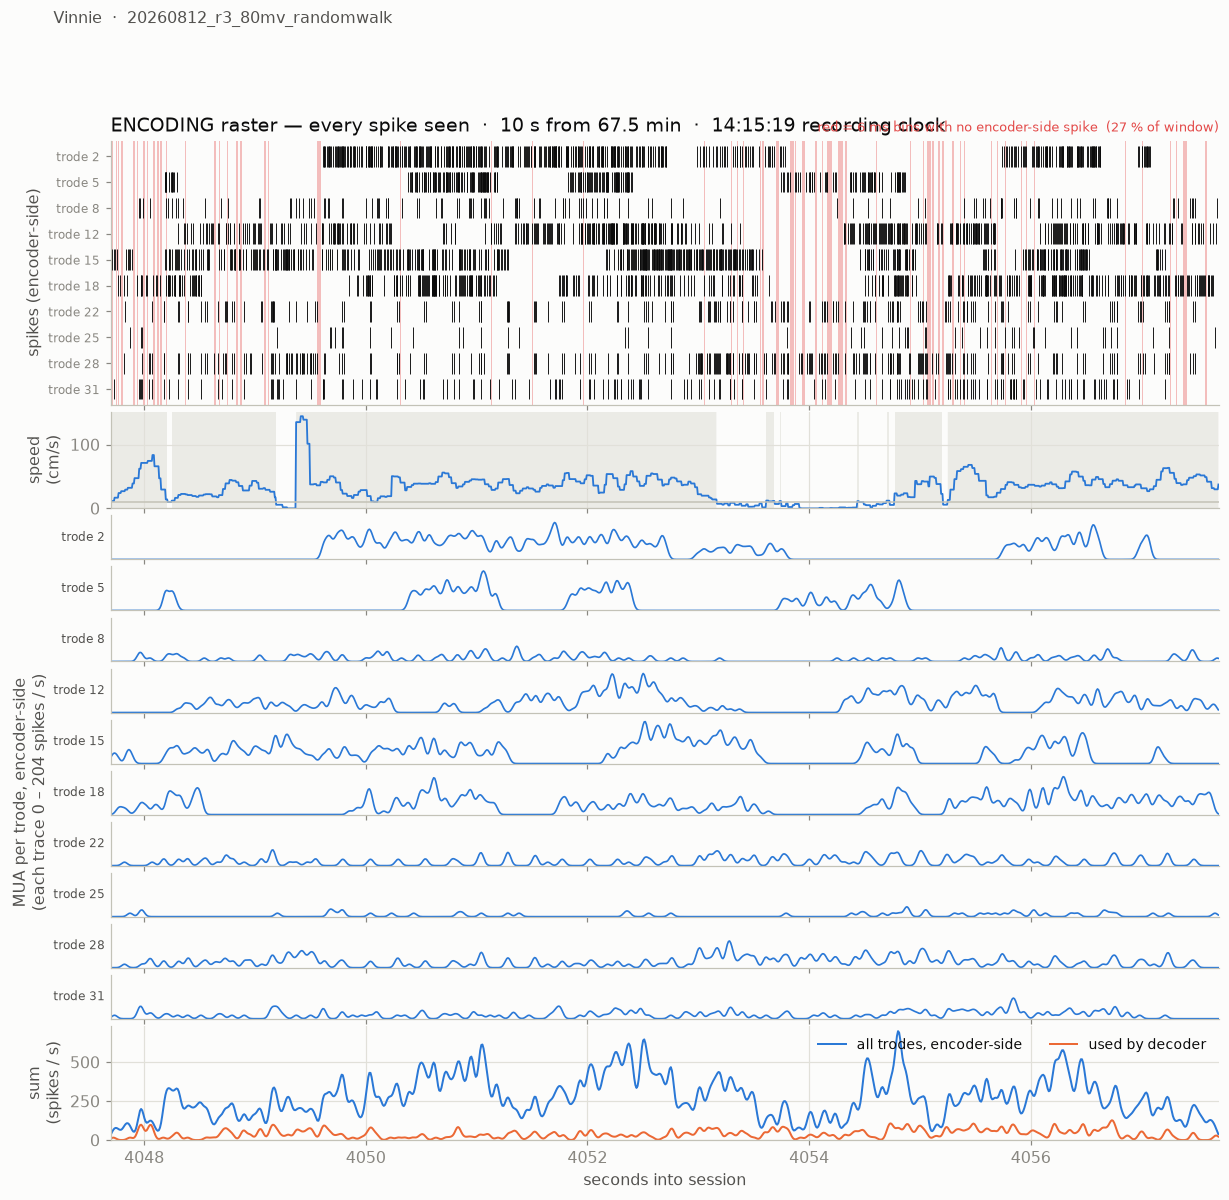

In [20]:
_ = plot_window(t_late, DEMO_DUR, source='encoder')

window 4047.7-4057.7 s: 2,749 spikes at encoder, 395 used by decoder (86 % lost)  ·  moving 83 % of the window  ·  bins with no decoder spikes 81 %, no encoder spikes 27 %


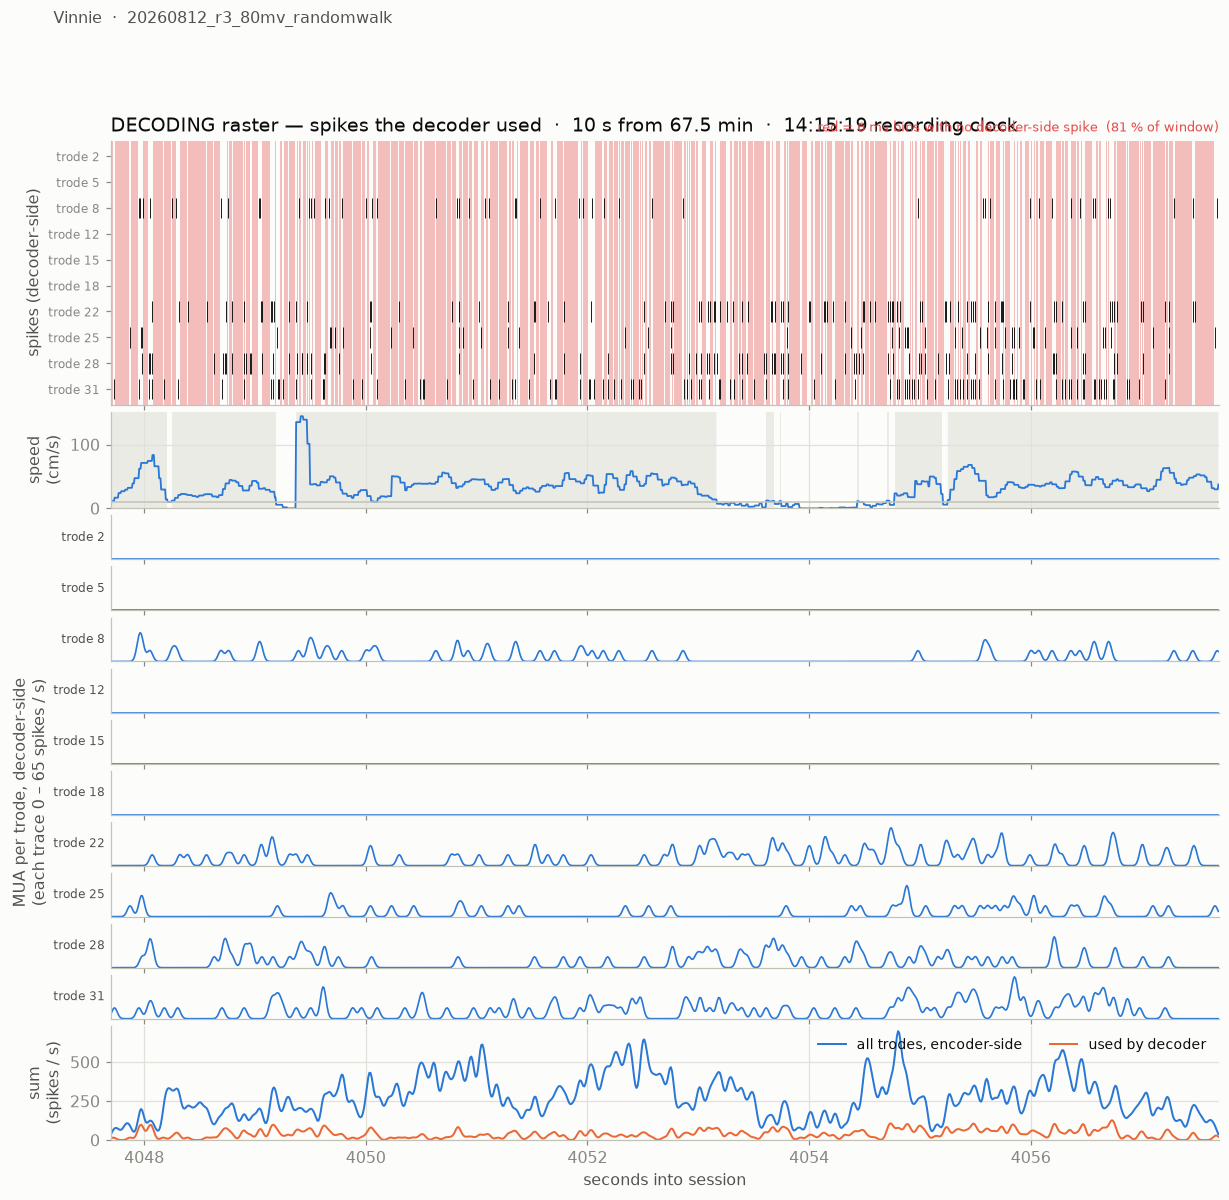

In [21]:
_ = plot_window(t_late, DEMO_DUR, source='decoder')

### Tiling the whole session into PDFs

**What it does.** Cuts the session into consecutive `TILE_DUR`-second windows and draws the window
plot for each one, one page per window, into **two PDFs in the run folder: `..._encoder.pdf` and
`..._decoder.pdf`**. Page *N* is the same window in both, so they can be opened side by side. A CSV
with one row per page (start time, recording-clock time, spikes seen / used, share of the window
spent moving, hexes visited) is written beside them so a page can be found by time, by hex, or by
how much was lost.

The MUA traces use one vertical scale for the *whole PDF* (the 99.9th percentile over the session),
so pages can be flipped through and compared directly. Pages are drawn as vector graphics (about
0.1 MB per page). They used to be partly rasterized, but matplotlib keeps every rasterized image in
memory until the PDF is closed — about 0.2 GB per page per PDF — which ran the kernel out of memory
partway through the session.

Set `TILE_SESSION = False` to skip this cell; it re-uses an existing PDF unless `OVERWRITE = True`.

In [22]:
from matplotlib.backends.backend_pdf import PdfPages
import time

TILE_SESSION = True
TILE_DUR     = 10.0
OVERWRITE    = False
PDF_BASE = os.path.join(RUN_DIR, f'{RUN_PREFIX}.raster_windows_{TILE_DUR:g}s')
PDF_PATHS = {'encoder': PDF_BASE + '_encoder.pdf', 'decoder': PDF_BASE + '_decoder.pdf'}
CSV_PATH  = PDF_BASE + '.csv'

def tile_session(dur=TILE_DUR, pdf_paths=PDF_PATHS, csv_path=CSV_PATH):
    starts = np.arange(0.0, bins.sec.iloc[-1], dur)
    # one MUA scale for the whole PDF
    edges_all = np.arange(0, bins.sec.iloc[-1] + dur, MUA_BIN_MS / 1e3)
    per_trode = [smooth(np.histogram(spk.sec[spk.trode == t], bins=edges_all)[0], MUA_BIN_MS) for t in TRODES]
    vmax = float(max(10, np.percentile(np.concatenate(per_trode), 99.9)))  # one scale for every page
    sources = ['encoder'] + (['decoder'] if spk_dec is not None else [])
    rows, t_start = [], time.time()
    pdfs = {src: PdfPages(pdf_paths[src]) for src in sources}
    try:
        # plt.ioff(): in Jupyter, every figure made in interactive mode is held until the cell ends
        # (to be shown afterwards), even after plt.close -- ~9 MB per page, ~8 GB for this session
        with plt.ioff():
            for k, t0 in enumerate(starts):
                for src in sources:
                    fig = plot_window(t0, dur, source=src, mua_vmax=vmax, show=False)
                    pdfs[src].savefig(fig); plt.close(fig)
                rows.append({'page': k + 1, **window_stats(t0, dur)})
                if (k + 1) % 50 == 0:
                    print(f'  {k + 1}/{len(starts)} pages  ({time.time() - t_start:.0f} s)')
    finally:
        for pdf in pdfs.values():
            pdf.close()
    index = pd.DataFrame(rows)
    num = index.columns.drop(['recording_time', 'hexes'])
    index[num] = index[num].round(1)
    index.to_csv(csv_path, index=False)
    return index

if not TILE_SESSION:
    print('TILE_SESSION is False — skipped.')
elif os.path.exists(PDF_PATHS['encoder']) and os.path.exists(CSV_PATH) and not OVERWRITE:
    page_index = pd.read_csv(CSV_PATH)
    for src, path in PDF_PATHS.items():
        if os.path.exists(path):
            print(f'already exists ({os.path.getsize(path)/1e6:.0f} MB, {len(page_index)} pages): {path}')
else:
    page_index = tile_session()
    for src, path in PDF_PATHS.items():
        if os.path.exists(path):
            print(f'wrote {len(page_index)} pages, {os.path.getsize(path)/1e6:.0f} MB -> {path}')
    print(f'index -> {CSV_PATH}')
page_index.head(10)

already exists (55 MB, 469 pages): /media/ssd1/decoder_output/Vinnie/20260812_r3_80mv_randomwalk/20260917_123501_Vinnie_hex_realtime_decoding.raster_windows_10s_encoder.pdf
already exists (41 MB, 469 pages): /media/ssd1/decoder_output/Vinnie/20260812_r3_80mv_randomwalk/20260917_123501_Vinnie_hex_realtime_decoding.raster_windows_10s_decoder.pdf


,page,t0_s,minute,recording_time,enc_spikes,dec_spikes,lost_%,moving_%,dec_zero_%,enc_zero_%,hexes
0,1,0.0,0.0,2026-08-12 13:07:52.168366592-07:00,4764,1722,63.9,46.0,43.4,16.1,1 40 35 29 34 39 43 48 3
1,2,10.0,0.2,2026-08-12 13:08:02.170366720-07:00,3908,2322,40.6,33.5,29.7,17.1,3
2,3,20.0,0.3,2026-08-12 13:08:12.172366592-07:00,6402,3973,37.9,89.1,11.3,6.0,3 48 43 39 34 29 35 40 45 41 36 31 26 22 21 17...
3,4,30.0,0.5,2026-08-12 13:08:22.168366592-07:00,4090,2792,31.7,26.5,25.3,19.8,8 6 4 1
4,5,40.0,0.7,2026-08-12 13:08:32.170366720-07:00,4198,3025,27.9,22.2,25.0,20.1,1 4 6 8 10 7 9
5,6,50.0,0.8,2026-08-12 13:08:42.172366592-07:00,5258,3863,26.5,71.8,14.2,8.8,9 12 15 16 20 25 21 26 22 27 38 2
6,7,60.0,1.0,2026-08-12 13:08:52.168366592-07:00,3911,2535,35.2,9.7,31.0,22.4,2
7,8,70.0,1.2,2026-08-12 13:09:02.170366720-07:00,5427,4269,21.3,71.6,11.1,8.0,2 49 38 32 27 22 26 21 31 36 41 45 40 35 29 34...
8,9,80.0,1.3,2026-08-12 13:09:12.172366592-07:00,4716,3727,21.0,58.6,17.5,14.2,3 48 43 39 34 29 35 40 45 41 36 31 26 21 25 20 16
9,10,90.0,1.5,2026-08-12 13:09:22.168366592-07:00,3853,2845,26.2,25.4,25.7,22.3,16 12 9 7 10 8 6 4 1


## Using the tables

```python
streaks_enc.query('duration_ms >= 500 and moving_frac > 0.5')       # long, while running — the interesting ones
streaks_enc.loc[streaks_enc.hex_at_start == 19]                    # every streak that began in hex 19
bins.loc[bins.enc_zero & bins.moving, ['recording_time', 'actual_hex', 'velocity']]
hex_mov.sort_values('enc_spikes_per_s')                             # weakest-covered hexes while moving
rate_by_trode.loc[19]                                              # which trodes fire in hex 19
spk.groupby(['hex', 'trode']).size().unstack()                     # raw spike counts, hex x trode
```

## Caveats

- **Sub-threshold spikes are invisible.** Everything here is relative to spikes whose peak mark
  exceeded `encoder.spk_amp`. A hex can look silent because cells there fire small, not because
  there are none. The hardware denominator cannot be recovered from these files.
- **Encoder-side is not loss-free either.** Each trode has its own encoder rank, and a busy rank can
  fall behind the live stream (its records' wall-clock lag grows to tens of seconds late in a long
  session). When that happens the spike stream feeding it drops chunks, and the raster for that trode
  shows firing in blocks separated by clean gaps of hundreds of ms that do not appear on quiet trodes.
  A late-session rise in the encoder-side no-spike fraction can therefore be pipeline loss too, one
  stage earlier. Check the busiest trodes' rows in the Section 8 raster before reading it as tissue.
- **Encoder-side ≠ evidence the decoder could have used.** Some encoder-side spikes had no KDE result
  (`cred_int = -1`, `enc_kde_spikes` counts those out); with `frozen_model: false` that is mainly the
  first spikes of each trode. It is a small correction here, and it is shown in the load cell.
- **The decoder-side map depends on the run, not just the recording.** The same `.rec` decoded twice
  gives the same encoder-side map and a different decoder-side map if the pipeline drops differed
  (playback pacing, encoder `bufsize`, `frozen_model`). Compare decoder-side maps across runs only
  with Section 2 in view.
- **Moving/still uses the *decoder's* velocity estimate** and the run's `encoder.vel_thresh`. The
  encoder only added spikes to its model above that speed, so still bins are decoded against a model
  that was never trained on still-state firing.
- **`hex_at_start` is one hex.** A long streak can span several; the per-hex streak map credits the
  whole streak to where it began.
- **Occupancy is uneven.** A few hexes hold most of the session and a few have only seconds. `MIN_BINS`
  hides the thinnest, but a 300-bin hex is still only 1.8 s of data.